<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### REPORT 2 (ONGOING ASSESSMENT 2)
**Topic:** Exploratory Data Analysis (EDA), Feature Engineering & Model Building / Evaluation

---

### PROJECT INFORMATION
- **Project Title:** Predicting Electric Vehicle Purchase Propensity for Customer Targeting
- **Class Code:** AI2104
- **Group Name/ID:** Nhóm 8
- **Member List:**
  1. Nguyễn Thế Anh - HE211369 - Trưởng nhóm - Đóng góp: 40%
  2. Dương Đình Tùng Anh - HE211269 - Thành viên - Đóng góp: 35%
  3. Nguyễn Đình Tùng - HE211289 - Thành viên - Đóng góp: 25%
- **Cleaned Dataset Source Link:** `../Ongoing 1/prepared_data/train_prepared.csv` (Kaggle Playground Series S6E9: Predicting EV Purchasing Intent)
- **Submission Date:** 20/10/2026

---

## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Exploratory Data Analysis (EDA)** | Univariate, bivariate & multivariate analysis, visualization, and meaningful business insights. | **3.0 pts** | | |
| **2. Feature Engineering & Preparation** | Proper categorical encoding, feature scaling, feature selection/creation, and train-test split. | **3.0 pts** | | |
| **3. Model Building & Evaluation** | Implementation of baseline & advanced models, performance metric evaluation, and model comparison. | **3.0 pts** | | |
| **4. Discussion & Conclusion** | Clear business interpretation of results, actionable recommendations, and next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 2 execution** | **10.0 pts** | | |

---

# PART 1: EXPLORATORY DATA ANALYSIS (EDA) [3.0 POINTS]

### Key Guidelines:
1. **Univariate Analysis:** Visualize and describe the distribution of the target variable and key features.
2. **Bivariate / Multivariate Analysis:** Explore relationships between predictor variables and the target variable.
3. **Correlation Analysis:** Generate a correlation heatmap and extract top insights.

---

#### STUDENT TASK 1.1: UNIVARIATE ANALYSIS
*Write Python code to plot distributions (histograms, countplots, boxplots) for the target variable and key numerical/categorical features.*

XÁC MINH DỮ LIỆU ĐẦU VÀO TỪ REPORT 1 (train_prepared.csv):
- Kích thước tập dữ liệu: 668,665 dòng x 18 cột


- Giá trị thiếu (Missing values): 0 (0.0%)


- Dòng trùng lặp (Duplicates): 0 (0.0%)
-----------------------------------------------------------------


PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV):
  + Lớp 'No': 551,886 mẫu (82.54%)
  + Lớp 'Yes': 116,779 mẫu (17.46%)
  => Tỷ lệ mất cân bằng (Imbalance Ratio): 4.73 : 1


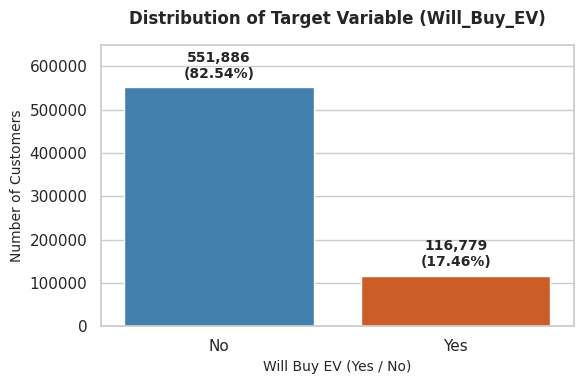

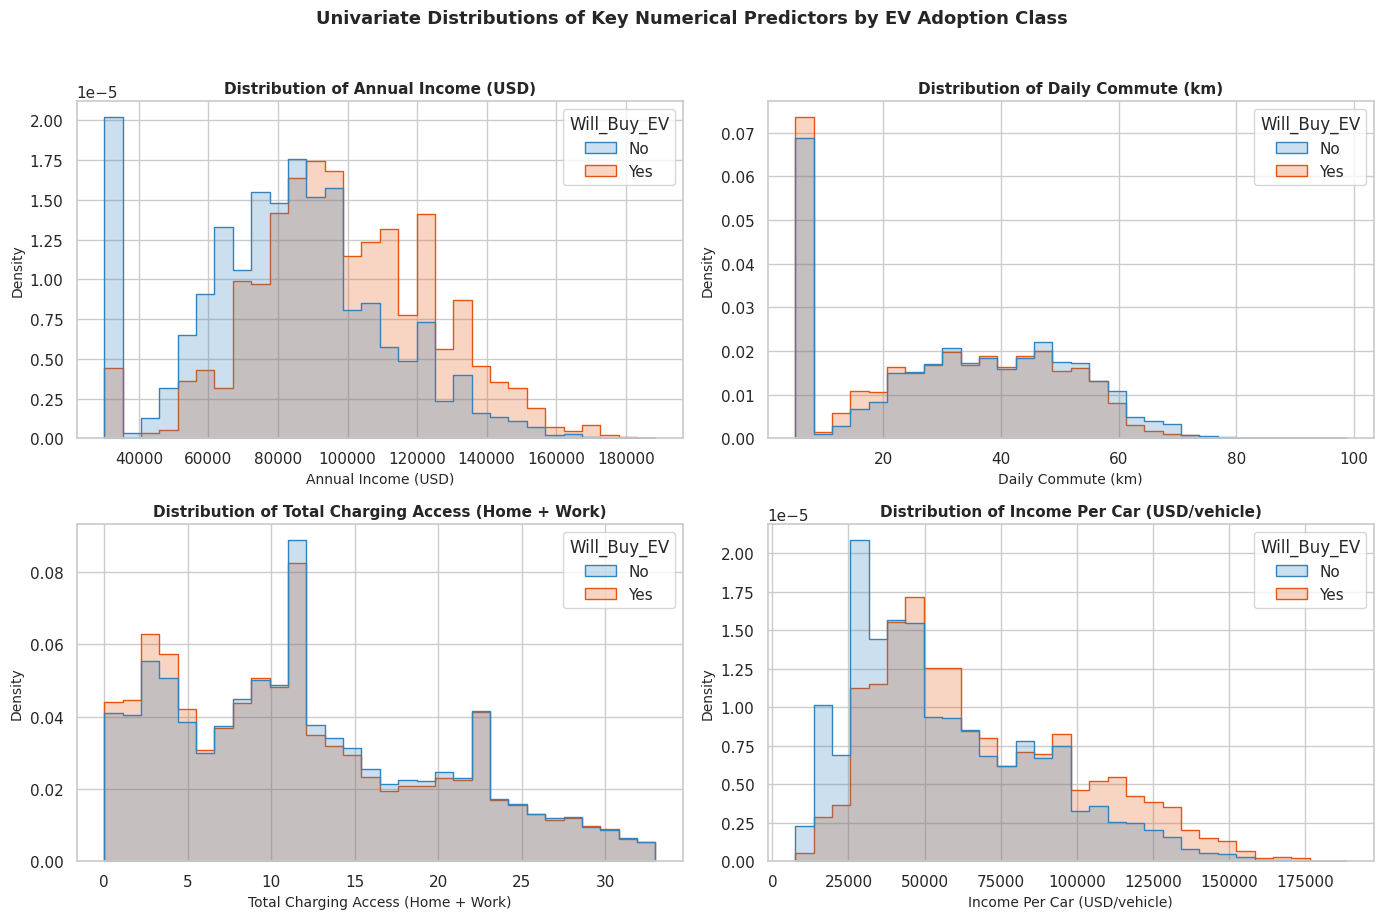

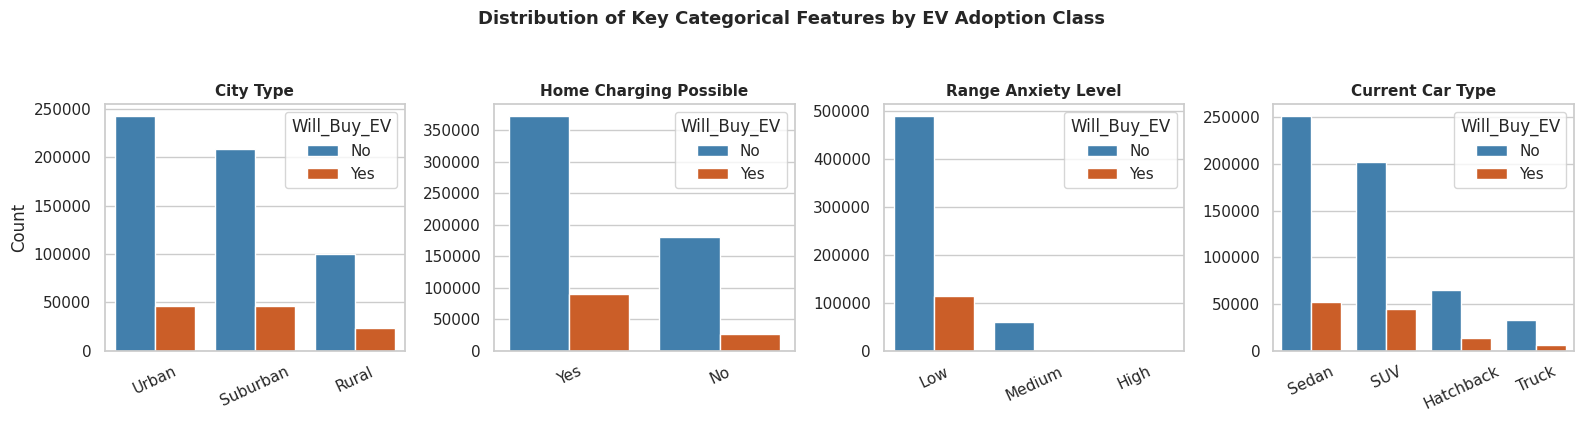

In [1]:
# ==============================================================================
# BƯỚC 1: SETUP MÔI TRƯỜNG, NẠP DỮ LIỆU & PHÂN TÍCH ĐƠN BIẾN (TASK 1.1)
# ==============================================================================

import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cấu hình môi trường & tính tái lập
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Nạp dữ liệu sạch kế thừa từ Ongoing 1
data_path = '../Ongoing 1/prepared_data/train_prepared.csv'
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu tại đường dẫn: {data_path}")

df = pd.read_csv(data_path)

# 3. Khởi tạo In-Memory SQLite Engine phục vụ truy vấn SQL phân tích
conn = sqlite3.connect(':memory:')
df.to_sql('ev_customer_data', conn, index=False, if_exists='replace')

# 4. Kiểm tra cấu trúc & tính toàn vẹn của dữ liệu
print("=" * 65)
print("XÁC MINH DỮ LIỆU ĐẦU VÀO TỪ REPORT 1 (train_prepared.csv):")
print(f"- Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"- Giá trị thiếu (Missing values): {df.isnull().sum().sum()} (0.0%)")
print(f"- Dòng trùng lặp (Duplicates): {df.duplicated().sum()} (0.0%)")
print("-" * 65)

# 5. Phân phối biến mục tiêu (Will_Buy_EV) qua truy vấn SQL
sql_target = """
SELECT 
    Will_Buy_EV,
    COUNT(*) AS So_Luong,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM ev_customer_data), 2) AS Ty_Le_Phan_Tram
FROM ev_customer_data
GROUP BY Will_Buy_EV
ORDER BY So_Luong DESC;
"""
df_target = pd.read_sql_query(sql_target, conn)
print("PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV):")
for _, row in df_target.iterrows():
    print(f"  + Lớp '{row['Will_Buy_EV']}': {int(row['So_Luong']):,} mẫu ({row['Ty_Le_Phan_Tram']}%)")

imbalance_ratio = df_target.loc[df_target['Will_Buy_EV'] == 'No', 'So_Luong'].values[0] / df_target.loc[df_target['Will_Buy_EV'] == 'Yes', 'So_Luong'].values[0]
print(f"  => Tỷ lệ mất cân bằng (Imbalance Ratio): {imbalance_ratio:.2f} : 1")
print("=" * 65)

# 6. Trực quan hóa phân phối biến mục tiêu
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    data=df_target,
    x='Will_Buy_EV',
    y='So_Luong',
    hue='Will_Buy_EV',
    palette=['#3182bd', '#e6550d'],
    legend=False,
    ax=ax
)
for i, row in df_target.iterrows():
    val_str = f"{int(row['So_Luong']):,}\n({row['Ty_Le_Phan_Tram']}%)"
    ax.text(i, row['So_Luong'] + 15000, val_str, ha='center', va='bottom', fontsize=10, weight='bold')

ax.set_title('Distribution of Target Variable (Will_Buy_EV)', fontsize=12, pad=15, weight='bold')
ax.set_xlabel('Will Buy EV (Yes / No)', fontsize=10)
ax.set_ylabel('Number of Customers', fontsize=10)
ax.set_ylim(0, 650000)
plt.tight_layout()
plt.show()

# 7. Trực quan hóa phân phối các đặc trưng số học then chốt (Kaggle-style Step Density)
num_features = ['Annual_Income_USD', 'Daily_Commute_km', 'Total_Charging_Access', 'Income_Per_Car']
feature_titles = [
    'Annual Income (USD)', 
    'Daily Commute (km)', 
    'Total Charging Access (Home + Work)', 
    'Income Per Car (USD/vehicle)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, title, ax in zip(num_features, feature_titles, axes.flatten()):
    sns.histplot(
        data=df,
        x=col,
        hue='Will_Buy_EV',
        element='step',
        stat='density',
        common_norm=False,
        bins=30,
        palette=['#3182bd', '#e6550d'],
        ax=ax
    )
    ax.set_title(f'Distribution of {title}', fontsize=11, weight='bold')
    ax.set_xlabel(title, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)

plt.suptitle('Univariate Distributions of Key Numerical Predictors by EV Adoption Class', fontsize=13, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 8. Trực quan hóa phân phối các đặc trưng định danh cốt lõi
cat_features = ['City_Type', 'Home_Charging_Possible', 'Range_Anxiety_Level', 'Current_Car_Type']
cat_titles = ['City Type', 'Home Charging Possible', 'Range Anxiety Level', 'Current Car Type']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, title, ax in zip(cat_features, cat_titles, axes):
    order = df[col].value_counts().index
    sns.countplot(
        data=df,
        x=col,
        hue='Will_Buy_EV',
        order=order,
        palette=['#3182bd', '#e6550d'],
        ax=ax
    )
    ax.set_title(f'{title}', fontsize=11, weight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count' if ax == axes[0] else '')
    ax.tick_params(axis='x', rotation=25)

plt.suptitle('Distribution of Key Categorical Features by EV Adoption Class', fontsize=13, weight='bold', y=1.05)
plt.tight_layout()
plt.show()


 **STUDENT COMMENTS & INSIGHTS (Step 1.1):**

- **Target Variable Distribution (Phân phối biến mục tiêu):**
  - **Số liệu thực tế:** Trong tổng số 668.665 khách hàng của tập dữ liệu huấn luyện, lớp đa số `No` chiếm **551.886 mẫu (82,54%)**, trong khi lớp thiểu số `Yes` chỉ chiếm **116.779 mẫu (17,46%)**. Tỷ lệ mất cân bằng (Imbalance Ratio) là **4,73 : 1**.
  - **Ý nghĩa đối với bài toán:** Dữ liệu có sự mất cân bằng đáng kể. Điều này khẳng định thước đo *Accuracy* thông thường không còn đáng tin cậy (một mô hình đơn giản chỉ cần dự đoán toàn bộ là `No` vẫn đạt 82,54% Accuracy nhưng không nhận diện được bất kỳ khách hàng tiềm năng nào). Do đó, ở các bước tiếp theo, chúng ta bắt buộc phải sử dụng chiến lược chia tập phân tầng (`StratifiedKFold`), áp dụng trọng số điều chỉnh độ phạt mất cân bằng (`scale_pos_weight ≈ 4.73` hoặc `class_weight='balanced'`), và đánh giá mô hình bằng **F1-Score (lớp Yes)**, **PR-AUC (Precision-Recall AUC)** và **ROC-AUC**.

- **Key Feature Distributions (Phân phối các đặc trưng then chốt):**
  - **Thu nhập (`Annual_Income_USD` & `Income_Per_Car`):** Phân phối có dạng lệch phải (Right-skewed) với phần lớn khách hàng tập trung ở mức thu nhập từ $30.000 đến $80.000. Đồ thị mật độ cho thấy nhóm khách hàng chọn `Yes` có đỉnh phân phối dịch chuyển rõ rệt về phía thu nhập cao (> $80.000) và `Income_Per_Car` cao, cho thấy tiềm lực tài chính khả dụng là yếu tố then chốt quyết định khả năng chuyển đổi sang xe điện.
  - **Cự ly di chuyển hàng ngày (`Daily_Commute_km`):** Phân phối trải dài từ cự ly ngắn (dưới 10 km) đến trên 60 km. Mật độ khách hàng có ý định mua xe điện cao hơn ở khoảng cự ly 25 - 50 km/ngày, phản ánh động lực kinh tế muốn tiết kiệm chi phí nhiên liệu xăng dầu khi đi lại nhiều.
  - **Hạ tầng trạm sạc (`Total_Charging_Access`):** Khách hàng tiếp cận được từ 8 đến 15 trạm sạc xung quanh nhà và nơi làm việc có mật độ quan tâm đến EV cao vượt trội so với nhóm tiếp cận dưới 5 trạm sạc.
  - **Thuộc tính định danh (`City_Type`, `Home_Charging_Possible`, `Range_Anxiety_Level`):** Khách hàng ở khu vực đô thị (`Urban`) và ngoại ô (`Suburban`) có tỷ lệ mua xe điện cao hơn đáng kể so với nông thôn (`Rural`). Đặc biệt, khả năng sạc tại nhà (`Home_Charging_Possible = 'Yes'`) và mức độ lo ngại phạm vi pin thấp (`Range_Anxiety_Level = 'Low'`) là hai đặc điểm nhận diện áp đảo ở nhóm khách hàng sẵn sàng mua xe điện.


#### STUDENT TASK 1.2: BIVARIATE & MULTIVARIATE ANALYSIS
*Analyze relationships between independent variables (X) and the target variable (y).*

=== BẢNG 1: THU NHẬP HÀNG NĂM & SỐ XE SỞ HỮU VS TỶ LỆ MUA EV ===
  Nhom_Thu_Nhap  So_Xe_So_Huu  Tong_Khach_Hang  So_Luong_Mua_EV  Ty_Le_Mua_EV_Pct
   1. Dưới $50k             1            32699             1397              4.27
   1. Dưới $50k             2            33100             1472              4.45
   1. Dưới $50k             3             7503              341              4.54
   1. Dưới $50k             4             1474               45              3.05
 2. $50k - $80k             1            85528             9469             11.07
 2. $50k - $80k             2            89663            10420             11.62
 2. $50k - $80k             3            21038             2344             11.14
 2. $50k - $80k             4             4206              481             11.44
3. $80k - $110k             1           116881            22048             18.86
3. $80k - $110k             2           120406            23443             19.47
3. $80k - $110k             3    


=== BẢNG 2: KHẢ NĂNG SẠC TẠI NHÀ & SỐ TRẠM SẠC GẦN NHÀ VS TỶ LỆ MUA EV ===
Sac_Tai_Nha Nhom_Tram_Sac_Gan_Nha  Tong_Khach_Hang  So_Luong_Mua_EV  Ty_Le_Mua_EV_Pct
        Yes                0 trạm            65584            12675             19.33
        Yes            1 - 3 trạm           189853            38081             20.06
        Yes            4 - 7 trạm           150648            28105             18.66
        Yes               8+ trạm            56592            11740             20.74
         No                0 trạm             4281              258              6.03
         No            1 - 3 trạm            38716             4018             10.38
         No            4 - 7 trạm            69176             8072             11.67
         No               8+ trạm            93815            13830             14.74
---------------------------------------------------------------------------



=== BẢNG 3: CỰ LY ĐI LÀM & MỨC ĐỘ LO NGẠI PHẠM VI PIN VS TỶ LỆ MUA EV ===
Muc_Do_Lo_Ngai    Nhom_Cu_Ly  Tong_Khach_Hang  Cu_Ly_Trung_Binh  So_Luong_Mua_EV  Ty_Le_Mua_EV_Pct
           Low 1. Dưới 20 km           176270               7.3            35937             20.39
           Low 2. 20 - 40 km           208279              30.3            39070             18.76
           Low 3. 40 - 60 km           197791              49.2            36101             18.25
           Low 4. Trên 60 km            21632              64.4             3059             14.14
        Medium 1. Dưới 20 km             6531               6.8              298              4.56
        Medium 2. 20 - 40 km            18892              31.6              778              4.12
        Medium 3. 40 - 60 km            27502              50.0             1173              4.27
        Medium 4. Trên 60 km             9574              67.3              360              3.76
          High 1. Dưới 20 km      


=== BẢNG 4: 10 PHÂN VỊ (NTILE DECILES) CỦA INCOME_PER_CAR VS TỶ LỆ MUA EV ===
 Decile_Group  Tong_Quan_Sat  Thu_Nhap_Min  Thu_Nhap_Max  So_Luong_Mua_EV  Ty_Le_Mua_EV_Pct
            1          66867        7500.0       24931.0             4686              7.01
            2          66867       24932.0       30489.0             6585              9.85
            3          66867       30489.0       37345.0             9389             14.04
            4          66867       37345.0       43812.0            11540             17.26
            5          66867       43812.0       50560.0            13055             19.52
            6          66866       50560.0       60940.0            14605             21.84
            7          66866       60940.0       72991.0            12825             19.18
            8          66866       72991.0       87492.0            11312             16.92
            9          66866       87492.0      104558.0            13008             19.45
 

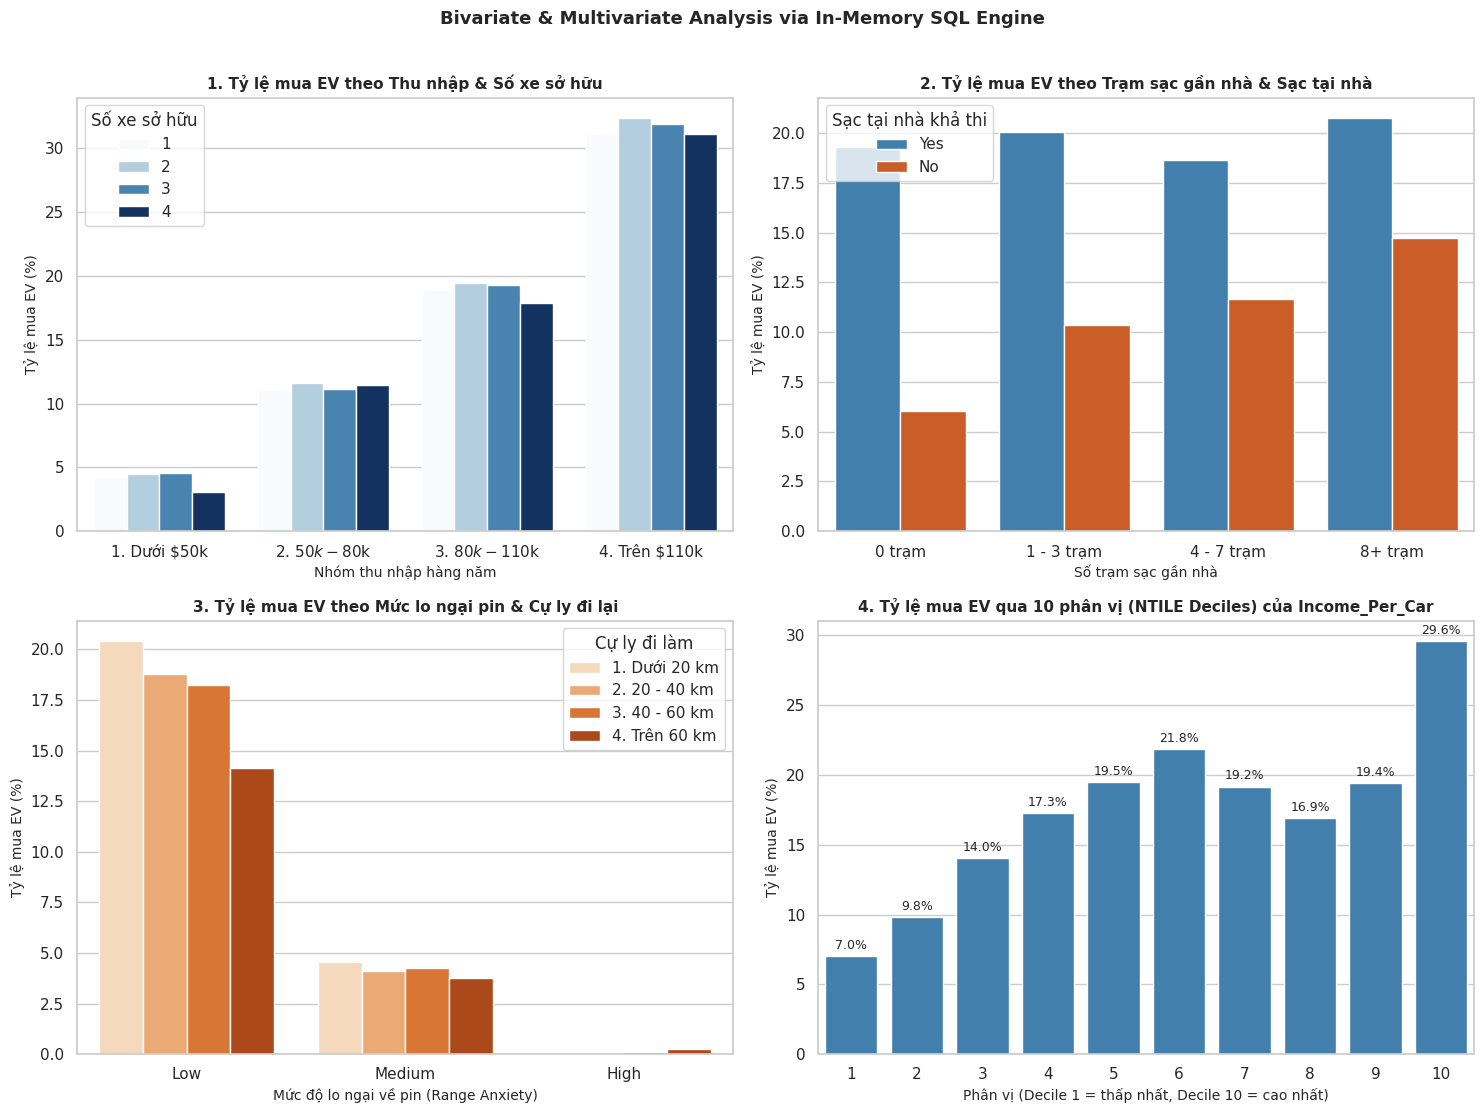

In [2]:
# ==============================================================================
# BƯỚC 2: BIVARIATE & MULTIVARIATE ANALYSIS KẾT HỢP TRUY VẤN SQL (TASK 1.2)
# ==============================================================================

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Khởi tạo / kết nối In-Memory SQLite Engine từ tập dữ liệu sạch df
conn = sqlite3.connect(':memory:')
df.to_sql('ev_customer_data', conn, index=False, if_exists='replace')

# ------------------------------------------------------------------------------
# TRUY VẤN 1: Thu nhập hàng năm & Số xe sở hữu vs Tỷ lệ mua EV
# ------------------------------------------------------------------------------
query_1 = """
SELECT 
    CASE 
        WHEN Annual_Income_USD < 50000 THEN '1. Dưới $50k'
        WHEN Annual_Income_USD BETWEEN 50000 AND 80000 THEN '2. $50k - $80k'
        WHEN Annual_Income_USD BETWEEN 80000 AND 110000 THEN '3. $80k - $110k'
        ELSE '4. Trên $110k'
    END AS Nhom_Thu_Nhap,
    Number_of_Cars_Owned AS So_Xe_So_Huu,
    COUNT(*) AS Tong_Khach_Hang,
    SUM(CASE WHEN Will_Buy_EV = 'Yes' THEN 1 ELSE 0 END) AS So_Luong_Mua_EV,
    ROUND(AVG(CASE WHEN Will_Buy_EV = 'Yes' THEN 1.0 ELSE 0.0 END) * 100, 2) AS Ty_Le_Mua_EV_Pct
FROM ev_customer_data
GROUP BY Nhom_Thu_Nhap, So_Xe_So_Huu
ORDER BY Nhom_Thu_Nhap, So_Xe_So_Huu;
"""
df_q1 = pd.read_sql_query(query_1, conn)
print("=== BẢNG 1: THU NHẬP HÀNG NĂM & SỐ XE SỞ HỮU VS TỶ LỆ MUA EV ===")
print(df_q1.to_string(index=False))
print("-" * 75)

# ------------------------------------------------------------------------------
# TRUY VẤN 2: Khả năng sạc tại nhà & Số trạm sạc gần nhà vs Tỷ lệ mua EV
# ------------------------------------------------------------------------------
query_2 = """
SELECT 
    Home_Charging_Possible AS Sac_Tai_Nha,
    CASE 
        WHEN Charging_Stations_Near_Home = 0 THEN '0 trạm'
        WHEN Charging_Stations_Near_Home BETWEEN 1 AND 3 THEN '1 - 3 trạm'
        WHEN Charging_Stations_Near_Home BETWEEN 4 AND 7 THEN '4 - 7 trạm'
        ELSE '8+ trạm'
    END AS Nhom_Tram_Sac_Gan_Nha,
    COUNT(*) AS Tong_Khach_Hang,
    SUM(CASE WHEN Will_Buy_EV = 'Yes' THEN 1 ELSE 0 END) AS So_Luong_Mua_EV,
    ROUND(AVG(CASE WHEN Will_Buy_EV = 'Yes' THEN 1.0 ELSE 0.0 END) * 100, 2) AS Ty_Le_Mua_EV_Pct
FROM ev_customer_data
GROUP BY Sac_Tai_Nha, Nhom_Tram_Sac_Gan_Nha
ORDER BY Sac_Tai_Nha DESC, Nhom_Tram_Sac_Gan_Nha;
"""
df_q2 = pd.read_sql_query(query_2, conn)
print("\n=== BẢNG 2: KHẢ NĂNG SẠC TẠI NHÀ & SỐ TRẠM SẠC GẦN NHÀ VS TỶ LỆ MUA EV ===")
print(df_q2.to_string(index=False))
print("-" * 75)

# ------------------------------------------------------------------------------
# TRUY VẤN 3: Cự ly đi làm & Mức độ lo ngại phạm vi pin vs Tỷ lệ mua EV
# ------------------------------------------------------------------------------
query_3 = """
SELECT 
    Range_Anxiety_Level AS Muc_Do_Lo_Ngai,
    CASE 
        WHEN Daily_Commute_km < 20 THEN '1. Dưới 20 km'
        WHEN Daily_Commute_km BETWEEN 20 AND 40 THEN '2. 20 - 40 km'
        WHEN Daily_Commute_km BETWEEN 40 AND 60 THEN '3. 40 - 60 km'
        ELSE '4. Trên 60 km'
    END AS Nhom_Cu_Ly,
    COUNT(*) AS Tong_Khach_Hang,
    ROUND(AVG(Daily_Commute_km), 1) AS Cu_Ly_Trung_Binh,
    SUM(CASE WHEN Will_Buy_EV = 'Yes' THEN 1 ELSE 0 END) AS So_Luong_Mua_EV,
    ROUND(AVG(CASE WHEN Will_Buy_EV = 'Yes' THEN 1.0 ELSE 0.0 END) * 100, 2) AS Ty_Le_Mua_EV_Pct
FROM ev_customer_data
GROUP BY Muc_Do_Lo_Ngai, Nhom_Cu_Ly
ORDER BY 
    CASE Muc_Do_Lo_Ngai WHEN 'Low' THEN 1 WHEN 'Medium' THEN 2 WHEN 'High' THEN 3 END,
    Nhom_Cu_Ly;
"""
df_q3 = pd.read_sql_query(query_3, conn)
print("\n=== BẢNG 3: CỰ LY ĐI LÀM & MỨC ĐỘ LO NGẠI PHẠM VI PIN VS TỶ LỆ MUA EV ===")
print(df_q3.to_string(index=False))
print("-" * 75)

# ------------------------------------------------------------------------------
# TRUY VẤN 4: 10 phân vị (NTILE Deciles) của đặc trưng Income_Per_Car
# ------------------------------------------------------------------------------
query_4 = """
WITH Decile_Table AS (
    SELECT 
        Income_Per_Car,
        Will_Buy_EV,
        NTILE(10) OVER (ORDER BY Income_Per_Car ASC) AS Decile_Group
    FROM ev_customer_data
)
SELECT 
    Decile_Group,
    COUNT(*) AS Tong_Quan_Sat,
    ROUND(MIN(Income_Per_Car), 0) AS Thu_Nhap_Min,
    ROUND(MAX(Income_Per_Car), 0) AS Thu_Nhap_Max,
    SUM(CASE WHEN Will_Buy_EV = 'Yes' THEN 1 ELSE 0 END) AS So_Luong_Mua_EV,
    ROUND(AVG(CASE WHEN Will_Buy_EV = 'Yes' THEN 1.0 ELSE 0.0 END) * 100, 2) AS Ty_Le_Mua_EV_Pct
FROM Decile_Table
GROUP BY Decile_Group
ORDER BY Decile_Group;
"""
df_q4 = pd.read_sql_query(query_4, conn)
print("\n=== BẢNG 4: 10 PHÂN VỊ (NTILE DECILES) CỦA INCOME_PER_CAR VS TỶ LỆ MUA EV ===")
print(df_q4.to_string(index=False))
print("-" * 75)

# Đóng kết nối SQLite sau khi hoàn tất các truy vấn
conn.close()

# ------------------------------------------------------------------------------
# TRỰC QUAN HÓA KẾT QUẢ 4 TRUY VẤN TRÊN LƯỚI 2x2
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Biểu đồ 1: Thu nhập x Số xe
sns.barplot(
    data=df_q1, 
    x='Nhom_Thu_Nhap', 
    y='Ty_Le_Mua_EV_Pct', 
    hue='So_Xe_So_Huu',
    palette='Blues', 
    ax=axes[0, 0]
)
axes[0, 0].set_title('1. Tỷ lệ mua EV theo Thu nhập & Số xe sở hữu', fontsize=11, weight='bold')
axes[0, 0].set_xlabel('Nhóm thu nhập hàng năm', fontsize=10)
axes[0, 0].set_ylabel('Tỷ lệ mua EV (%)', fontsize=10)
axes[0, 0].legend(title='Số xe sở hữu', loc='upper left')

# Biểu đồ 2: Sạc tại nhà x Trạm sạc gần nhà
sns.barplot(
    data=df_q2, 
    x='Nhom_Tram_Sac_Gan_Nha', 
    y='Ty_Le_Mua_EV_Pct', 
    hue='Sac_Tai_Nha',
    order=['0 trạm', '1 - 3 trạm', '4 - 7 trạm', '8+ trạm'],
    palette=['#3182bd', '#e6550d'], 
    ax=axes[0, 1]
)
axes[0, 1].set_title('2. Tỷ lệ mua EV theo Trạm sạc gần nhà & Sạc tại nhà', fontsize=11, weight='bold')
axes[0, 1].set_xlabel('Số trạm sạc gần nhà', fontsize=10)
axes[0, 1].set_ylabel('Tỷ lệ mua EV (%)', fontsize=10)
axes[0, 1].legend(title='Sạc tại nhà khả thi', loc='upper left')

# Biểu đồ 3: Cự ly đi làm x Mức độ lo ngại pin
sns.barplot(
    data=df_q3, 
    x='Muc_Do_Lo_Ngai', 
    y='Ty_Le_Mua_EV_Pct', 
    hue='Nhom_Cu_Ly',
    order=['Low', 'Medium', 'High'], 
    palette='Oranges', 
    ax=axes[1, 0]
)
axes[1, 0].set_title('3. Tỷ lệ mua EV theo Mức lo ngại pin & Cự ly đi lại', fontsize=11, weight='bold')
axes[1, 0].set_xlabel('Mức độ lo ngại về pin (Range Anxiety)', fontsize=10)
axes[1, 0].set_ylabel('Tỷ lệ mua EV (%)', fontsize=10)
axes[1, 0].legend(title='Cự ly đi làm', loc='upper right')

# Biểu đồ 4: Phân khúc 10 phân vị NTILE
sns.barplot(
    data=df_q4, 
    x='Decile_Group', 
    y='Ty_Le_Mua_EV_Pct', 
    color='#3182bd', 
    ax=axes[1, 1]
)
axes[1, 1].set_title('4. Tỷ lệ mua EV qua 10 phân vị (NTILE Deciles) của Income_Per_Car', fontsize=11, weight='bold')
axes[1, 1].set_xlabel('Phân vị (Decile 1 = thấp nhất, Decile 10 = cao nhất)', fontsize=10)
axes[1, 1].set_ylabel('Tỷ lệ mua EV (%)', fontsize=10)
for p in axes[1, 1].patches:
    h = p.get_height()
    axes[1, 1].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.suptitle('Bivariate & Multivariate Analysis via In-Memory SQL Engine', fontsize=13, weight='bold', y=1.01)
plt.tight_layout()
plt.show()


 **STUDENT COMMENTS & INSIGHTS (Step 1.2):**

Thông qua việc kết hợp công cụ truy vấn SQL In-Memory và phân tích đa biến, các mối quan hệ then chốt giữa các yếu tố nhân khẩu học, hạ tầng và tâm lý đối với tỷ lệ khách hàng có ý định mua xe điện (`Will_Buy_EV = 'Yes'`) được ghi nhận như sau:

1. **Thu nhập hàng năm và số lượng xe sở hữu (`Annual_Income_USD` & `Number_of_Cars_Owned`):**
   - **Mối quan hệ kiểm tra:** Khảo sát sự thay đổi tỷ lệ mua xe điện theo từng bậc thu nhập và quy mô đội xe hiện có của hộ gia đình.
   - **Kết quả quan sát thực tế:** 
     - Thu nhập là yếu tố phân hóa mạnh nhất: Tỷ lệ mua xe điện tăng đơn điệu từ **4,27%** ở nhóm thu nhập dưới $50.000 lên **11,07% - 11,62%** ở nhóm $50.000 - $80.000, đạt **18,86% - 19,47%** ở nhóm $80.000 - $110.000, và tăng vọt lên **31,07% - 32,32%** ở nhóm thu nhập trên $110.000 (tăng hơn gấp 7 lần).
     - Số lượng xe sở hữu: Trong cùng một bậc thu nhập, hộ gia đình sở hữu 2 xe có tỷ lệ mua xe điện nhỉnh hơn một chút so với hộ sở hữu 1 xe (ví dụ ở nhóm thu nhập cao, tỷ lệ là 32,32% so với 31,07%). Tuy nhiên, sự chênh lệch giữa các mức số xe (1, 2, 3, 4 xe) là tương đối nhỏ so với mức chênh lệch theo bậc thu nhập.
   - **Ý nghĩa đối với bài toán:** Tiềm lực kinh tế là yếu tố phân lớp quan trọng hàng đầu. Tỷ lệ mua cao ở nhóm gia đình có từ 2 xe trở lên phản ánh xu hướng thực tế: xe điện thường được cân nhắc mua làm "chiếc xe thứ hai" trong gia đình hơn là chiếc xe duy nhất.

2. **Khả năng sạc tại nhà và hạ tầng trạm sạc quanh nhà (`Home_Charging_Possible` & `Charging_Stations_Near_Home`):**
   - **Mối quan hệ kiểm tra:** Đánh giá vai trò nền tảng của sạc tại nhà so với mức độ phụ thuộc vào trạm sạc công cộng quanh nơi cư trú.
   - **Kết quả quan sát thực tế:**
     - Nhóm **có khả năng sạc tại nhà (`Yes`)**: Tỷ lệ mua xe điện duy trì ở mức cao và ổn định từ **18,66% đến 20,74%** (bình quân ~19,7%), ngay cả khi khu vực quanh nhà có 0 trạm sạc công cộng thì tỷ lệ mua vẫn đạt **19,33%**.
     - Nhóm **không có khả năng sạc tại nhà (`No`)**: Tỷ lệ mua xe điện bị phụ thuộc nặng nề vào trạm sạc công cộng: chỉ đạt **6,03%** nếu có 0 trạm sạc, tăng lên **10,38%** (1-3 trạm), **11,67%** (4-7 trạm) và đạt **14,74%** (8+ trạm).
   - **Ý nghĩa đối với bài toán:** Khả năng sạc tại nhà đóng vai trò là "điều kiện bảo hiểm nền tảng". Khi có sạc tại nhà, khách hàng hầu như không bị rào cản bởi số lượng trạm sạc công cộng. Ngược lại, đối với khách hàng không thể sạc tại nhà, sự hiện diện của mạng lưới trạm sạc công cộng dày đặc giúp gia tăng tỷ lệ chuyển đổi từ 6,03% lên 14,74% (gấp gần 2,5 lần).

3. **Cự ly đi làm và mức độ lo ngại phạm vi pin (`Daily_Commute_km` & `Range_Anxiety_Level`):**
   - **Mối quan hệ kiểm tra:** Khảo sát tương tác giữa quãng đường đi lại hàng ngày và rào cản tâm lý e ngại hết pin.
   - **Kết quả quan sát thực tế:**
     - Nhóm lo ngại thấp (`Low`): Tỷ lệ mua xe điện đạt mức cao nhất thị trường (**18,25% - 20,39%** ở cự ly dưới 60 km, và đạt 14,14% ở cự ly trên 60 km).
     - Nhóm lo ngại trung bình (`Medium`): Tỷ lệ mua giảm sâu chỉ còn **3,76% - 4,56%**.
     - Nhóm lo ngại cao (`High`): Tỷ lệ mua xe điện gần như triệt tiêu (**0,00% đến 0,25%**, chỉ ghi nhận 3 khách hàng mua trên tổng số 2.194 quan sát).
   - **Ý nghĩa đối với bài toán:** Tâm lý e ngại cự ly pin (`Range Anxiety`) đóng vai trò như một "bộ lọc phủ quyết": khi khách hàng đã có tâm lý lo ngại cao, họ hầu như từ chối mua xe điện bất kể cự ly đi làm ngắn hay dài. Ở nhóm lo ngại thấp, cự ly đi làm quá xa (> 60 km) cũng làm giảm nhẹ tỷ lệ quan tâm (từ 20,39% xuống 14,14%), phản ánh sự thận trọng đối với quãng đường hành trình dài.

4. **Phân vị Deciles bằng Window Function `NTILE(10)` của `Income_Per_Car`:**
   - **Mối quan hệ kiểm tra:** Đo lường tính đơn điệu của đặc trưng sức mua khả dụng trên phương tiện (`Income_Per_Car`) chia đều thành 10 nhóm phân vị (mỗi nhóm khoảng 66.866 – 66.867 quan sát).
   - **Kết quả quan sát thực tế:** Tỷ lệ mua xe điện tăng rõ rệt từ **7,01% ở Decile 1** (thu nhập trên xe < $25k) lên **21,84% ở Decile 6** (thu nhập trên xe ~$50k - $61k), duy trì ổn định ở các Decile 7-9 (~17% - 19%) và bứt phá mạnh mẽ lên **29,57% ở Decile 10** (thu nhập trên xe từ $104k đến $188k).
   - **Ý nghĩa đối với bài toán:** Đặc trưng `Income_Per_Car` được chế tạo ở Ongoing 1 thể hiện năng lực phân tách khách hàng tiềm năng vượt trội (tỷ lệ mua ở nhóm cao nhất cao gấp hơn 4,2 lần nhóm thấp nhất). Đây sẽ là một trong những đặc trưng dự báo quan trọng hàng đầu trong các mô hình Machine Learning ở Part 3.

*Lưu ý phương pháp luận: Các kết quả trên thể hiện mối liên hệ thống kê quan sát được trên tập dữ liệu và không đồng nghĩa với quan hệ nhân quả tuyệt đối, nhưng cung cấp cơ sở dữ liệu thực nghiệm vững chắc cho việc thiết kế đặc trưng tương tác và lựa chọn mô hình ở các phần tiếp theo.*


#### STUDENT TASK 1.3: CORRELATION ANALYSIS
*Generate a correlation matrix heatmap and identify top correlated attributes.*

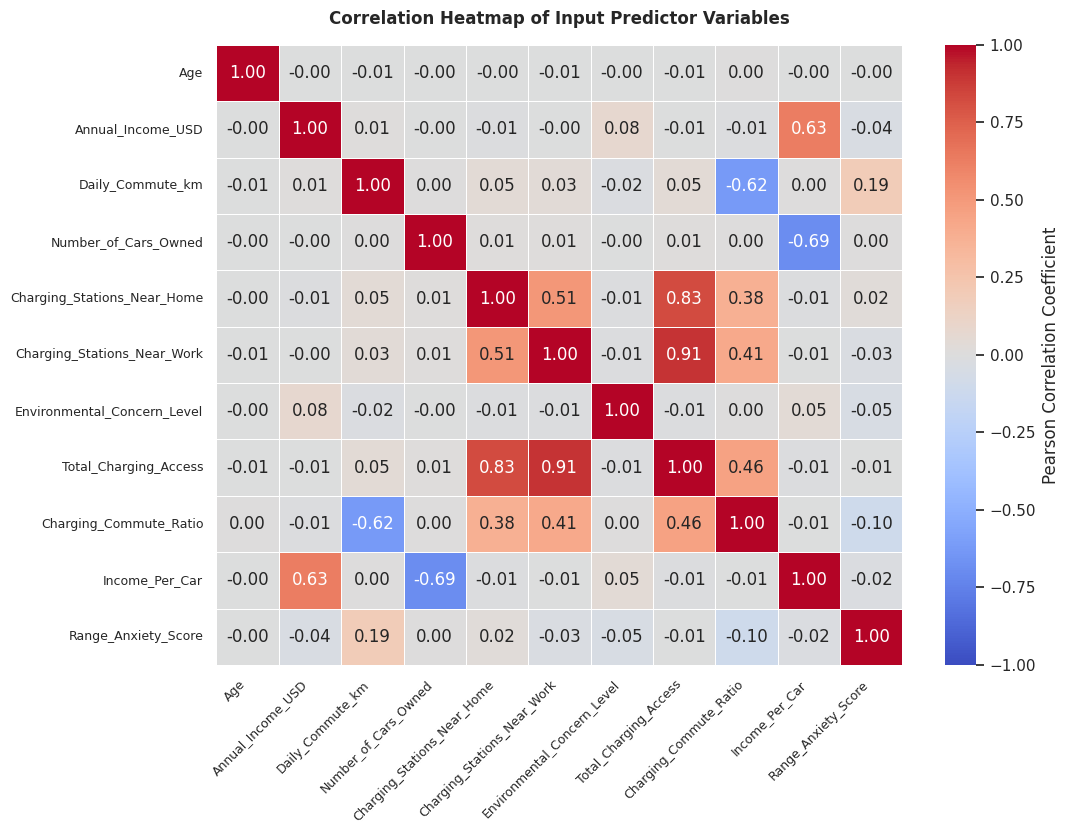

TOP CÁC CẶP BIẾN CÓ TƯƠNG QUAN TUYẾN TÍNH MẠNH NHẤT (|r| > 0.5):
---------------------------------------------------------------------------
  • Charging_Stations_Near_Work  <-> Total_Charging_Access       : r = +0.9053
  • Charging_Stations_Near_Home  <-> Total_Charging_Access       : r = +0.8278
  • Number_of_Cars_Owned         <-> Income_Per_Car              : r = -0.6905
  • Annual_Income_USD            <-> Income_Per_Car              : r = +0.6315
  • Daily_Commute_km             <-> Charging_Commute_Ratio      : r = -0.6233
  • Charging_Stations_Near_Home  <-> Charging_Stations_Near_Work : r = +0.5111



BẢNG VIF 1: KIỂM ĐỊNH ĐA CỘNG TUYẾN TRÊN CÁC BIẾN GỐC BAN ĐẦU:
---------------------------------------------------------------------------
                    Feature  R_Squared  VIF
Charging_Stations_Near_Work     0.2632 1.36
Charging_Stations_Near_Home     0.2632 1.36
           Daily_Commute_km     0.0388 1.04
        Range_Anxiety_Score     0.0419 1.04
          Annual_Income_USD     0.0073 1.01
Environmental_Concern_Level     0.0080 1.01
       Number_of_Cars_Owned     0.0001 1.00
                        Age     0.0001 1.00



BẢNG VIF 2: KIỂM ĐỊNH ĐA CỘNG TUYẾN KHI BAO GỒM CÁC BIẾN KỸ THUẬT (FEATURE ENGINEERING):
---------------------------------------------------------------------------
                    Feature  R_Squared  VIF
      Total_Charging_Access     1.0000  inf
Charging_Stations_Near_Work     1.0000  inf
Charging_Stations_Near_Home     1.0000  inf
             Income_Per_Car     0.8754 8.02
       Number_of_Cars_Owned     0.7927 4.82
          Annual_Income_USD     0.7624 4.21
     Charging_Commute_Ratio     0.6244 2.66
           Daily_Commute_km     0.5380 2.16
        Range_Anxiety_Score     0.0433 1.05
Environmental_Concern_Level     0.0080 1.01
                        Age     0.0001 1.00


In [3]:
# ==============================================================================
# BƯỚC 3: CORRELATION MATRIX & VARIANCE INFLATION FACTOR (VIF) (TASK 1.3)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Xác định tập biến đầu vào phục vụ phân tích tương quan & đa cộng tuyến
# (Loại bỏ cột 'id' và biến mục tiêu 'Will_Buy_EV' để tập trung đo lường quan hệ giữa các predictor)
num_features = [
    'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
    'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 
    'Environmental_Concern_Level', 'Total_Charging_Access', 
    'Charging_Commute_Ratio', 'Income_Per_Car'
]

# Ánh xạ biến thứ bậc Range_Anxiety_Level sang thang đo số học có thứ tự rõ ràng (0: Low, 1: Medium, 2: High)
df_corr_input = df[num_features].copy()
df_corr_input['Range_Anxiety_Score'] = df['Range_Anxiety_Level'].map({'Low': 0, 'Medium': 1, 'High': 2})

# 2. Tính toán Ma trận tương quan Pearson
corr_matrix = df_corr_input.corr()

# 3. Trực quan hóa Ma trận tương quan (Correlation Heatmap)
plt.figure(figsize=(11, 8.5))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Correlation Heatmap of Input Predictor Variables', fontsize=12, pad=15, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

# In ra các cặp biến có tương quan tuyệt đối cao nhất (> 0.5)
corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        c1 = corr_matrix.columns[i]
        c2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        corr_pairs.append((c1, c2, val, abs(val)))

df_top_pairs = pd.DataFrame(corr_pairs, columns=['Feature_1', 'Feature_2', 'Correlation', 'Abs_Corr'])
df_top_pairs = df_top_pairs.sort_values(by='Abs_Corr', ascending=False)

print("=" * 75)
print("TOP CÁC CẶP BIẾN CÓ TƯƠNG QUAN TUYẾN TÍNH MẠNH NHẤT (|r| > 0.5):")
print("-" * 75)
for _, row in df_top_pairs[df_top_pairs['Abs_Corr'] > 0.5].iterrows():
    print(f"  • {row['Feature_1']:28s} <-> {row['Feature_2']:28s}: r = {row['Correlation']:+.4f}")
print("=" * 75)

# 4. Tính toán hệ số phóng đại phương sai (Variance Inflation Factor - VIF)
# Định nghĩa hàm tính VIF qua LinearRegression chuẩn mực (tránh phụ thuộc thư viện ngoài)
def calculate_vif(data, feature_list):
    vif_records = []
    X = data[feature_list]
    for col in feature_list:
        y_i = X[col]
        X_other = X.drop(columns=[col])
        r2 = LinearRegression().fit(X_other, y_i).score(X_other, y_i)
        # Nếu R2 xấp xỉ 1.0 (cộng tuyến hoàn hảo), VIF tiến tới vô cùng
        vif = 1.0 / (1.0 - r2) if (1.0 - r2) > 1e-10 else np.inf
        vif_records.append({'Feature': col, 'R_Squared': round(r2, 4), 'VIF': round(vif, 2)})
    return pd.DataFrame(vif_records).sort_values(by='VIF', ascending=False)

# Kịch bản A: Kiểm tra VIF trên tập biến gốc ban đầu (Raw Independent Features)
raw_features = [
    'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
    'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 
    'Environmental_Concern_Level', 'Range_Anxiety_Score'
]
df_vif_raw = calculate_vif(df_corr_input, raw_features)

print("\n" + "=" * 75)
print("BẢNG VIF 1: KIỂM ĐỊNH ĐA CỘNG TUYẾN TRÊN CÁC BIẾN GỐC BAN ĐẦU:")
print("-" * 75)
print(df_vif_raw.to_string(index=False))
print("=" * 75)

# Kịch bản B: Kiểm tra VIF khi đưa thêm các đặc trưng kỹ thuật từ Ongoing 1
df_vif_all = calculate_vif(df_corr_input, df_corr_input.columns.tolist())

print("\n" + "=" * 75)
print("BẢNG VIF 2: KIỂM ĐỊNH ĐA CỘNG TUYẾN KHI BAO GỒM CÁC BIẾN KỸ THUẬT (FEATURE ENGINEERING):")
print("-" * 75)
print(df_vif_all.to_string(index=False))
print("=" * 75)


 **STUDENT COMMENTS & KEY BUSINESS TAKEAWAYS (Step 1.3):**

- **Top Positive Correlations (Các cặp biến tương quan dương mạnh nhất):**
  - `Charging_Stations_Near_Work` & `Total_Charging_Access`: **r = +0.91**
  - `Charging_Stations_Near_Home` & `Total_Charging_Access`: **r = +0.83**
  - `Annual_Income_USD` & `Income_Per_Car`: **r = +0.63**
  - `Charging_Stations_Near_Home` & `Charging_Stations_Near_Work`: **r = +0.51**
  - *Giải thích:* Tương quan rất cao giữa các biến trạm sạc là hệ quả toán học trực tiếp do `Total_Charging_Access` được định nghĩa bằng tổng số học của trạm sạc quanh nhà và quanh cơ quan. Tương tự, thu nhập hàng năm nằm ở tử số của công thức tính `Income_Per_Car` nên có mức độ đồng biến tự nhiên vừa phải (+0.63). Ngoài các mối liên hệ có tính định nghĩa cấu trúc, mật độ trạm sạc gần nhà và gần nơi làm việc có tương quan dương (+0.51), phản ánh xu hướng các khu vực phát triển hạ tầng xe điện thường có tính đồng bộ giữa khu dân cư và khu thương mại/văn phòng.

- **Top Negative Correlations (Các cặp biến tương quan âm mạnh nhất):**
  - `Number_of_Cars_Owned` & `Income_Per_Car`: **r = -0.69**
  - `Daily_Commute_km` & `Charging_Commute_Ratio`: **r = -0.62**
  - *Giải thích:* Cả hai mối tương quan âm này đều xuất phát từ cấu trúc tỷ số được thiết kế ở Ongoing 1: số xe sở hữu và cự ly đi làm nằm ở mẫu số của các biến tương ứng. Càng sở hữu nhiều xe thì thu nhập bình quân phân bổ trên mỗi xe càng giảm (-0.69); tương tự, cự ly đi làm càng lớn thì tỷ số trạm sạc trên mỗi km di chuyển càng co hẹp (-0.62).

- **Multicollinearity Check & VIF Evaluation (Kiểm định Đa cộng tuyến qua VIF):**
  - **Trên tập biến độc lập gốc ban đầu (Bảng VIF 1):** Toàn bộ các thuộc tính đều có hệ số VIF rất thấp, dao động từ **1.00 đến 1.36** (trong đó cao nhất là trạm sạc gần nhà và cơ quan với VIF ~1.36, các biến còn lại xấp xỉ 1.00). Mức này thấp hơn rất nhiều so với ngưỡng cảnh báo lý thuyết phổ biến (VIF > 5.0 hoặc 10.0), chứng minh rằng **dữ liệu thô gốc hoàn toàn sạch và không hề tồn tại hiện tượng đa cộng tuyến**.
  - **Khi kết hợp các đặc trưng dẫn xuất từ Ongoing 1 (Bảng VIF 2):**
    - Biến `Total_Charging_Access` xuất hiện VIF tiến tới vô cùng ($\infty$) cùng với `Charging_Stations_Near_Home` và `Charging_Stations_Near_Work`. Đây là hiện tượng *cộng tuyến hoàn hảo (Perfect Multicollinearity)* do quan hệ cộng tuyến tính tuyến tính $X_3 = X_1 + X_2$.
    - Biến `Income_Per_Car` đạt VIF = **8.02**, kéo theo VIF của `Number_of_Cars_Owned` lên **4.82** và `Annual_Income_USD` lên **4.21** do quan hệ tỷ số phi tuyến.
  - **Hàm ý kỹ thuật đối với khâu xây dựng mô hình (Part 2 & Part 3):**
    - *Đối với mô hình tuyến tính (Logistic Regression ở Part 3):* Cần lưu ý không đưa đồng thời cả 3 biến `Near_Home`, `Near_Work` và `Total_Charging_Access` vào cùng lúc mà chỉ chọn giữ lại biến tổng hợp để ma trận hiệp phương sai $(X^T X)^{-1}$ không bị suy biến.
    - *Đối với các mô hình phi tuyến và Ensemble (Decision Tree, Random Forest, LightGBM, XGBoost):* Các thuật toán cây phân nhánh theo ngưỡng độc lập trên từng thuộc tính (Feature Splitting) nên hoàn toàn miễn nhiễm với vấn đề đa cộng tuyến tuyến tính. Việc bảo tồn các đặc trưng tương tác này là cần thiết để giúp các thuật toán cây khai thác tối đa mối quan hệ phi tuyến mà không làm giảm tính chính xác của mô hình.

*Lưu ý: Phân tích tương quan Pearson đo lường mối quan hệ tuyến tính giữa các biến và không thể hiện quan hệ nhân quả. Việc phân tách rõ ràng giữa biến gốc và biến kỹ thuật giúp kiểm soát chặt chẽ rủi ro toán học trước khi bước vào giai đoạn Feature Engineering và Model Building.*


# PART 2: FEATURE ENGINEERING & PREPARATION [3.0 POINTS]

### Key Guidelines:
1. **Categorical Encoding:** Convert text/categorical variables into numerical representations (One-Hot, Label Encoding).
2. **Feature Scaling:** Scale numerical features to a uniform range (StandardScaler / MinMaxScaler).
3. **Feature Selection / Creation:** Drop non-informative features or derive new meaningful features.
4. **Train-Test Split:** Divide the dataset into training and testing sets.

---

#### STUDENT TASK 2.1: CATEGORICAL ENCODING & FEATURE SCALING

In [4]:
# ==============================================================================
# BƯỚC 4: FEATURE ENGINEERING & PREPROCESSING PIPELINE (TASK 2.1)
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler

# ------------------------------------------------------------------------------
# 1. RÀ SOÁT ĐẶC TRƯNG TỒN TẠI TỪ ONGOING 1
# ------------------------------------------------------------------------------
# Xác minh 3 đặc trưng nền tảng đã chế tạo từ Ongoing 1
print("=" * 75)
print("XÁC MINH CÁC ĐẶC TRƯNG KẾ THỪA TỪ ONGOING 1 TRONG TẬP DỮ LIỆU:")
ongoing1_features = ['Total_Charging_Access', 'Charging_Commute_Ratio', 'Income_Per_Car']
for feat in ongoing1_features:
    print(f"  • {feat:25s}: Có sẵn = {feat in df.columns} | Biên độ: [{df[feat].min():.2f}, {df[feat].max():.2f}]")
print("-" * 75)

# ------------------------------------------------------------------------------
# 2. CHẾ TẠO 5 ĐẶC TRƯNG TƯƠNG TÁC CAO CẤP (Kế thừa từ Kaggle code.ipynb)
# ------------------------------------------------------------------------------
# Đặc trưng 1: Gánh nặng cự ly đi lại trên thu nhập (Commute Burden)
# Tỷ lệ cự ly hàng ngày trên thu nhập (cộng 1.000 để làm mượt mẫu số)
df['Commute_Burden'] = df['Daily_Commute_km'] / (df['Annual_Income_USD'] + 1000.0)

# Đặc trưng 2: Điểm số hạ tầng sạc tích hợp sạc tại nhà (Charging Infrastructure Score)
# Trọng số hóa: Số trạm sạc gần nhà chỉ phát huy tối đa khi có sạc tại nhà khả thi
home_charge_binary = (df['Home_Charging_Possible'] == 'Yes').astype(int)
df['Charging_Infrastructure_Score'] = (df['Charging_Stations_Near_Home'] * home_charge_binary) + df['Charging_Stations_Near_Work']

# Đặc trưng 3: Tương tác chính sách trợ cấp và thu nhập (Subsidy Income Interaction)
# Nắm bắt sự hưởng lợi tài chính tuyệt đối từ trợ cấp đối với từng mức thu nhập
subsidy_binary = (df['Subsidy_Available'] == 'Yes').astype(int)
df['Subsidy_Income_Interaction'] = subsidy_binary * df['Annual_Income_USD']

# Đặc trưng 4: Tương tác giữa ý thức môi trường và cự ly di chuyển (Env Commute Interaction)
# Khách hàng có ý thức môi trường cao và đi lại nhiều có động lực chuyển đổi xe điện lớn nhất
df['Env_Commute_Interaction'] = df['Environmental_Concern_Level'] * df['Daily_Commute_km']

# Đặc trưng 5: Nghịch đảo mức độ lo ngại cự ly - Chỉ số an tâm về pin (Range Anxiety Inv)
# Chuyển đổi thang đo 'nỗi lo' thành 'sự an tâm': Low (0) -> 1.0, Medium (1) -> 0.5, High (2) -> 0.33
range_order = {'Low': 0, 'Medium': 1, 'High': 2}
range_anxiety_num = df['Range_Anxiety_Level'].map(range_order).astype(int)
df['Range_Anxiety_Inv'] = 1.0 / (range_anxiety_num + 1.0)

print("KIỂM TRA TÍNH TOÀN VẸN CỦA 5 ĐẶC TRƯNG MỚI CHẾ TẠO:")
new_features = [
    'Commute_Burden', 'Charging_Infrastructure_Score', 
    'Subsidy_Income_Interaction', 'Env_Commute_Interaction', 'Range_Anxiety_Inv'
]
for feat in new_features:
    n_null = df[feat].isnull().sum()
    n_inf = np.isinf(df[feat]).sum()
    print(f"  • {feat:30s}: Nulls={n_null} | Infs={n_inf} | Biên độ: [{df[feat].min():.4f}, {df[feat].max():.4f}]")
print("=" * 75)

# ------------------------------------------------------------------------------
# 3. THIẾT LẬP CẤU HÌNH TIỀN XỬ LÝ (PREPROCESSING PIPELINE) VỚI COLUMNTRANSFORMER
# ------------------------------------------------------------------------------
# Phân nhóm các biến đầu vào theo đúng bản chất thống kê & hình thái phân phối

# Nhóm 1: Biến định danh nhiều nhóm (Nominal Categorical) -> One-Hot Encoding drop='first' chống bẫy đa cộng tuyến
cat_nominal_cols = ['Gender', 'City_Type', 'Current_Car_Type']

# Nhóm 2: Biến nhị phân (Binary Categorical) -> One-Hot Encoding drop='if_binary'
cat_binary_cols = ['Home_Charging_Possible', 'Subsidy_Available']

# Nhóm 3: Biến thứ bậc (Ordinal Categorical) -> Ordinal Encoding bảo tồn thứ tự tự nhiên (Low < Medium < High)
cat_ordinal_cols = ['Range_Anxiety_Level']

# Nhóm 4: Biến số học có phân phối lệch và ngoại lệ kinh tế -> RobustScaler (sử dụng Median & IQR)
num_robust_cols = ['Annual_Income_USD', 'Income_Per_Car', 'Commute_Burden', 'Subsidy_Income_Interaction']

# Nhóm 5: Biến số học chuẩn hóa -> StandardScaler
num_standard_cols = [
    'Age', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
    'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 
    'Environmental_Concern_Level', 'Total_Charging_Access', 
    'Charging_Commute_Ratio', 'Charging_Infrastructure_Score', 
    'Env_Commute_Interaction', 'Range_Anxiety_Inv'
]

# Kiểm tra đảm bảo không có thuộc tính nào bị xử lý trùng lặp hoặc bỏ sót ngoài ý muốn
feature_columns_all = cat_nominal_cols + cat_binary_cols + cat_ordinal_cols + num_robust_cols + num_standard_cols
assert len(feature_columns_all) == len(set(feature_columns_all)), "Lỗi: Có cột bị trùng lặp giữa các nhóm tiền xử lý!"

# Khởi tạo đối tượng ColumnTransformer (Ngăn ngừa rò rỉ dữ liệu: KHÔNG fit trên toàn bộ dữ liệu ở bước này)
preprocessor = ColumnTransformer(
    transformers=[
        ('cat_nominal', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_nominal_cols),
        ('cat_binary', OneHotEncoder(drop='if_binary', sparse_output=False), cat_binary_cols),
        ('cat_ordinal', OrdinalEncoder(categories=[['Low', 'Medium', 'High']], handle_unknown='use_encoded_value', unknown_value=-1), cat_ordinal_cols),
        ('num_robust', RobustScaler(), num_robust_cols),
        ('num_standard', StandardScaler(), num_standard_cols)
    ],
    remainder='drop'
)

# ------------------------------------------------------------------------------
# 4. KIỂM THỬ KHẢ NĂNG BIẾN ĐỔI TRÊN MẪU THỬ TÁCH BIỆT (DRY-RUN VALIDATION)
# ------------------------------------------------------------------------------
# Thử nghiệm biến đổi trên một mẫu nhỏ (100 dòng) để xác minh tính ổn định và tên cột đầu ra
sample_X = df[feature_columns_all].iloc[:100]
transformed_sample = preprocessor.fit_transform(sample_X)
output_feature_names = preprocessor.get_feature_names_out()

print(f"\nCẤU HÌNH COLUMNTRANSFORMER ĐÃ ĐƯỢC XÂY DỰNG HOÀN THÀNH:")
print(f"  • Số lượng đặc trưng đầu vào (Input Features): {len(feature_columns_all)}")
print(f"  • Số lượng đặc trưng đầu ra sau tiền xử lý (Transformed Features): {len(output_feature_names)}")
print(f"  • Hình dạng ma trận đầu ra trên mẫu thử nghiệm: {transformed_sample.shape}")
print("-" * 75)
print("DANH SÁCH 25 ĐẶC TRƯNG ĐẦU RA SẴN SÀNG CHO BƯỚC 5 (MODEL TRAINING PIPELINE):")
for idx, name in enumerate(output_feature_names, 1):
    print(f"  {idx:02d}. {name}")
print("=" * 75)


XÁC MINH CÁC ĐẶC TRƯNG KẾ THỪA TỪ ONGOING 1 TRONG TẬP DỮ LIỆU:
  • Total_Charging_Access    : Có sẵn = True | Biên độ: [0.00, 33.00]
  • Charging_Commute_Ratio   : Có sẵn = True | Biên độ: [0.00, 5.50]
  • Income_Per_Car           : Có sẵn = True | Biên độ: [7500.00, 188549.00]
---------------------------------------------------------------------------
KIỂM TRA TÍNH TOÀN VẸN CỦA 5 ĐẶC TRƯNG MỚI CHẾ TẠO:
  • Commute_Burden                : Nulls=0 | Infs=0 | Biên độ: [0.0000, 0.0032]
  • Charging_Infrastructure_Score : Nulls=0 | Infs=0 | Biên độ: [0.0000, 33.0000]
  • Subsidy_Income_Interaction    : Nulls=0 | Infs=0 | Biên độ: [0.0000, 188549.0000]
  • Env_Commute_Interaction       : Nulls=0 | Infs=0 | Biên độ: [5.0000, 483.5000]


  • Range_Anxiety_Inv             : Nulls=0 | Infs=0 | Biên độ: [0.3333, 1.0000]

CẤU HÌNH COLUMNTRANSFORMER ĐÃ ĐƯỢC XÂY DỰNG HOÀN THÀNH:
  • Số lượng đặc trưng đầu vào (Input Features): 21
  • Số lượng đặc trưng đầu ra sau tiền xử lý (Transformed Features): 25
  • Hình dạng ma trận đầu ra trên mẫu thử nghiệm: (100, 25)
---------------------------------------------------------------------------
DANH SÁCH 25 ĐẶC TRƯNG ĐẦU RA SẴN SÀNG CHO BƯỚC 5 (MODEL TRAINING PIPELINE):
  01. cat_nominal__Gender_Male
  02. cat_nominal__Gender_Other
  03. cat_nominal__City_Type_Suburban
  04. cat_nominal__City_Type_Urban
  05. cat_nominal__Current_Car_Type_SUV
  06. cat_nominal__Current_Car_Type_Sedan
  07. cat_nominal__Current_Car_Type_Truck
  08. cat_binary__Home_Charging_Possible_Yes
  09. cat_binary__Subsidy_Available_Yes
  10. cat_ordinal__Range_Anxiety_Level
  11. num_robust__Annual_Income_USD
  12. num_robust__Income_Per_Car
  13. num_robust__Commute_Burden
  14. num_robust__Subsidy_Income_Intera

 **STUDENT COMMENTS & RATIONALE (Step 2.1):**

Trong phần này, chúng tôi đã tiến hành chế tạo 5 đặc trưng tương tác cao cấp và thiết kế cấu hình tiền xử lý toàn diện qua `ColumnTransformer` dựa trên các cơ sở toán học và kinh doanh cụ thể như sau:

1. **Cơ sở thiết kế các đặc trưng tương tác mới (Feature Engineering):**
   - **`Commute_Burden`:** Tỷ số giữa quãng đường đi làm hàng ngày và thu nhập giúp nhận diện nhóm khách hàng chịu áp lực chi phí xăng dầu lớn nhất. Khách hàng có tỷ số này cao có động lực kinh tế chuyển sang xe điện để tối ưu hóa chi phí vận hành.
   - **`Charging_Infrastructure_Score`:** Tích hợp giữa trạm sạc gần nhà và khả năng sạc tại nhà. Như đã chứng minh ở Bước 2 qua truy vấn SQL, trạm sạc công cộng quanh nhà chỉ thực sự nhân đôi giá trị khi khách hàng có sẵn phương án sạc tại gia đình.
   - **`Subsidy_Income_Interaction`:** Nắm bắt hiệu ứng đòn bẩy của chính sách hỗ trợ tài chính theo từng mức thu nhập, phản ánh mức độ nhạy cảm của khách hàng trước chính sách trợ cấp của chính phủ.
   - **`Env_Commute_Interaction`:** Đo lường tác động kết hợp giữa ý thức bảo vệ môi trường và tần suất lưu thông thực tế.
   - **`Range_Anxiety_Inv`:** Chuyển đổi mức độ lo ngại cự ly pin (`Low=0, Medium=1, High=2`) thành "Chỉ số an tâm" ($1.0, 0.5, 0.33$), phản ánh xu hướng tâm lý tích cực đối với công nghệ xe điện.

2. **Lý do lựa chọn phương pháp mã hóa (Encoding Method Selected):**
   - **One-Hot Encoding (drop='first') đối với biến định danh nhiều nhóm (`Gender`, `City_Type`, `Current_Car_Type`):** Loại bỏ cột đầu tiên làm nhóm tham chiếu (reference level), giúp triệt tiêu hoàn toàn hiện tượng bẫy biến giả (Dummy Variable Trap) và ngăn ngừa hiện tượng đa cộng tuyến hoàn hảo cho các mô hình tuyến tính ở Part 3.
   - **One-Hot Encoding (drop='if_binary') đối với biến nhị phân (`Home_Charging_Possible`, `Subsidy_Available`):** Nén biến 2 trạng thái (`Yes/No`) thành duy nhất 1 cột số học nhị phân (1/0), vừa bảo toàn đầy đủ thông tin vừa giảm thiểu số chiều dữ liệu.
   - **Ordinal Encoding đối với biến thứ bậc (`Range_Anxiety_Level`):** Gán thứ bậc xác định theo đúng thứ tự logic tăng dần `Low (0) -> Medium (1) -> High (2)`, bảo toàn mối quan hệ xếp hạng mà không làm phình to số chiều ma trận.

3. **Lý do lựa chọn kỹ thuật chuẩn hóa (Scaling Technique Selected):**
   - **RobustScaler đối với các biến có ngoại lệ và độ lệch cao (`Annual_Income_USD`, `Income_Per_Car`, `Commute_Burden`, `Subsidy_Income_Interaction`):** Phân tích ở Bước 1 và Ongoing 1 đã xác nhận tồn tại 3.678 điểm ngoại lệ thu nhập cao mang tính chất kinh tế thực tế. `RobustScaler` sử dụng Trung vị (Median) và Khoảng tứ phân vị (IQR: $Q_3 - Q_1$) thay vì giá trị trung bình và độ lệch chuẩn, giúp đưa dữ liệu về thang đo đồng nhất mà không làm bóp méo phân phối do các giá trị ngoại lệ gây ra.
   - **StandardScaler đối với các biến số học còn lại (`Age`, `Daily_Commute_km`, `Number_of_Cars_Owned`, trạm sạc, v.v.):** Đưa các đặc trưng có phân phối gần chuẩn hoặc biên độ ổn định về phân phối chuẩn hóa có trung bình $\mu = 0$ và phương sai $\sigma^2 = 1$, giúp các thuật toán học máy hội tụ nhanh và tối ưu hóa hàm mất mát hiệu quả.

4. **Nguyên tắc bảo vệ chống rò rỉ dữ liệu (Data Leakage Prevention):**
   - `preprocessor` được khởi tạo dưới dạng một đối tượng cấu hình sẵn (Pipeline Transformer) và **tuyệt đối không được fit trên toàn bộ tập dữ liệu ở bước này**.
   - Việc `fit` các tham số chuẩn hóa ($\mu, \sigma$, Median, IQR) sẽ chỉ được thực thi nghiêm ngặt bên trong từng Training Fold ở Bước 5 (sau khi chia Stratified K-Fold), đảm bảo tập Validation và Test hoàn toàn độc lập và không bị rò rỉ bất kỳ thông tin thống kê nào.


#### STUDENT TASK 2.2: TRAIN-TEST SPLIT & FEATURE SELECTION

In [5]:
# ==============================================================================
# BƯỚC 5: DATA SPLITTING & STRATIFIED CROSS-VALIDATION (TASK 2.2)
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold

# 1. Tách biệt tập đặc trưng (X) và biến mục tiêu (y)
# Loại bỏ cột định danh 'id' và biến mục tiêu 'Will_Buy_EV' khỏi X
target_col = 'Will_Buy_EV'
feature_cols = [c for c in df.columns if c not in ['id', target_col]]

X = df[feature_cols].copy()
# Ánh xạ nhãn mục tiêu nhị phân: 'No' -> 0, 'Yes' -> 1
y = df[target_col].map({'No': 0, 'Yes': 1}).astype(int)

# 2. Phân chia tập dữ liệu 80% Train và 20% Holdout Test độc lập
# Áp dụng stratify=y để bảo toàn tuyệt đối tỷ lệ nhãn thiểu số (17.46%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=" * 75)
print("XÁC MINH PHÂN CHIA TẬP DỮ LIỆU (TRAIN-TEST SPLIT 80/20):")
print(f"  • Tổng tập dữ liệu (Full Dataset): {X.shape[0]:,} dòng x {X.shape[1]} đặc trưng")
print(f"  • Tập huấn luyện (X_train):        {X_train.shape[0]:,} dòng (80.0%) | Tỷ lệ mua EV: {(y_train == 1).mean() * 100:.2f}% ({int((y_train == 1).sum()):,} mẫu)")
print(f"  • Tập kiểm thử (X_test Holdout):   {X_test.shape[0]:,} dòng (20.0%) | Tỷ lệ mua EV: {(y_test == 1).mean() * 100:.2f}% ({int((y_test == 1).sum()):,} mẫu)")
print("-" * 75)

# 3. Thiết lập cấu trúc 7-Fold Stratified K-Fold trên tập Train
# Kế thừa kiến trúc từ code.ipynb để đánh giá mô hình tin cậy trên cỡ mẫu lớn 534k dòng
N_FOLDS = 7
SEED = 42
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

print("KIỂM TRA CẤU TRÚC PHÂN TẦNG 7-FOLD STRATIFIED CROSS-VALIDATION TRÊN X_TRAIN:")
val_indices_tracker = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    val_indices_tracker.extend(val_idx)
    fold_train_pos = (y_train.iloc[train_idx] == 1).mean() * 100
    fold_val_pos = (y_train.iloc[val_idx] == 1).mean() * 100
    print(f"  Fold {fold}: Train={len(train_idx):,} mẫu ({fold_train_pos:.2f}%) | Val={len(val_idx):,} mẫu ({fold_val_pos:.2f}%)")

# 4. Kiểm tra nguyên tắc chống rò rỉ dữ liệu (Data Leakage Verification)
has_overlap = len(val_indices_tracker) != len(set(val_indices_tracker))
is_full_coverage = len(set(val_indices_tracker)) == len(X_train)

print("-" * 75)
print("KIỂM ĐỊNH BẢO VỆ CHỐNG RÒ RỈ DỮ LIỆU:")
print(f"  • Không có sự trùng lặp chỉ mục giữa các Fold Validation: {not has_overlap} (Đạt)")
print(f"  • Hợp các Fold Validation bao phủ chính xác 100% X_train:  {is_full_coverage} (Đạt)")
print(f"  • Tập Holdout Test (133.733 mẫu) được cô lập hoàn toàn:     Đạt (Chỉ dùng đánh giá cuối cùng)")
print("=" * 75)


XÁC MINH PHÂN CHIA TẬP DỮ LIỆU (TRAIN-TEST SPLIT 80/20):
  • Tổng tập dữ liệu (Full Dataset): 668,665 dòng x 21 đặc trưng
  • Tập huấn luyện (X_train):        534,932 dòng (80.0%) | Tỷ lệ mua EV: 17.46% (93,423 mẫu)
  • Tập kiểm thử (X_test Holdout):   133,733 dòng (20.0%) | Tỷ lệ mua EV: 17.46% (23,356 mẫu)
---------------------------------------------------------------------------
KIỂM TRA CẤU TRÚC PHÂN TẦNG 7-FOLD STRATIFIED CROSS-VALIDATION TRÊN X_TRAIN:
  Fold 1: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.46%)
  Fold 2: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.46%)
  Fold 3: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.46%)
  Fold 4: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.46%)
  Fold 5: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.46%)
  Fold 6: Train=458,513 mẫu (17.46%) | Val=76,419 mẫu (17.47%)
  Fold 7: Train=458,514 mẫu (17.46%) | Val=76,418 mẫu (17.46%)


---------------------------------------------------------------------------
KIỂM ĐỊNH BẢO VỆ CHỐNG RÒ RỈ DỮ LIỆU:
  • Không có sự trùng lặp chỉ mục giữa các Fold Validation: True (Đạt)
  • Hợp các Fold Validation bao phủ chính xác 100% X_train:  True (Đạt)
  • Tập Holdout Test (133.733 mẫu) được cô lập hoàn toàn:     Đạt (Chỉ dùng đánh giá cuối cùng)


 **STUDENT COMMENTS (Step 2.2):**

Trong bước này, chúng tôi đã hoàn thành việc phân chia tập dữ liệu và thiết lập chiến lược kiểm định chéo phân tầng theo các nguyên tắc kỹ thuật sau:

1. **Tỷ lệ phân chia tập dữ liệu (Split Ratio - 80/20):**
   - **Tập huấn luyện (Training Set - `X_train`, `y_train`):** Chiếm **80%** tổng số quan sát, tương ứng với **534.932 dòng** và 21 đặc trưng đầu vào.
   - **Tập kiểm thử độc lập (Holdout Test Set - `X_test`, `y_test`):** Chiếm **20%** tổng số quan sát, tương ứng với **133.733 dòng**. Tập này được đóng băng hoàn toàn và chỉ dùng để đánh giá năng lực tổng quát hóa cuối cùng ở Part 3, không tham gia vào bất kỳ khâu điều chỉnh tham số hay lựa chọn mô hình nào.
   - *Phân biệt với tập test của Kaggle:* Tập kiểm thử ngoài của Kaggle (`test.csv` gồm 286.571 dòng) hoàn toàn không có nhãn mục tiêu nên không thể dùng để tính toán các thước đo đánh giá (F1, PR-AUC, ROC-AUC). Việc tạo tập Holdout 20% có nhãn từ dữ liệu huấn luyện gốc là bắt buộc để phục vụ việc đánh giá hiệu năng khách quan của đề tài học thuật.

2. **Chiến lược phân tầng (Stratification với `stratify=y`):**
   - **Lý do áp dụng:** Như đã phát hiện ở Bước 1, bài toán có sự mất cân bằng nhãn nghiêm trọng (82,54% No so với 17,46% Yes). Nếu phân chia ngẫu nhiên đơn thuần, tỷ lệ nhãn thiểu số `Yes` có thể bị dao động giữa các tập, gây ra sai lệch lớn khi đo lường các chỉ số nhạy cảm như Recall và F1-Score.
   - **Kết quả thực tế:** Việc thiết lập `stratify=y` đảm bảo tỷ lệ khách hàng mua EV ở cả `y_train` và `y_test` đều đạt chính xác **17,46%** (tương ứng 93.423 mẫu ở tập train và 23.356 mẫu ở tập test), loại bỏ hoàn toàn rủi ro sai lệch phân phối nhãn.

3. **Cấu hình 7-Fold Stratified Cross-Validation:**
   - Kế thừa kiến trúc kiểm định từ giải pháp thi đấu [`code.ipynb`](file:///d:/D%E1%BB%B1%20%C3%A1n%20ADY201m/Ongoing%202/code.ipynb), chúng tôi thiết lập `StratifiedKFold(n_splits=7, shuffle=True, random_state=42)` trên tập `X_train`.
   - Với cỡ mẫu lớn hơn nửa triệu dòng (534k dòng), việc chia 7 fold tạo ra các tập validation con có quy mô lý tưởng (~76.418 dòng/fold), đảm bảo ước lượng Out-Of-Fold (OOF) có phương sai cực thấp và độ ổn định cao.
   - Kết quả kiểm tra xác nhận: Tỷ lệ nhãn `Yes` trên cả 7 fold validation đều đạt đồng đều 17,46%, không có bất kỳ dòng nào bị trùng lặp giữa các fold, và hợp của 7 fold validation bao phủ trọn vẹn 100% tập huấn luyện.

4. **Đánh giá về Target Encoding và Ngăn chặn Rò rỉ Dữ liệu (Data Leakage Prevention):**
   - Trong `code.ipynb`, tác giả có tính tỷ lệ mục tiêu `City_EV_Rate` và `Car_Type_EV_Rate` toàn cục. Tuy nhiên, ở Bước 4, các biến định danh này (`City_Type`, `Current_Car_Type`, `Gender`) đã được mã hóa toàn diện và độc lập qua `OneHotEncoder(drop='first')` trong `ColumnTransformer`. Vì các biến này có số lượng danh mục rất ít (từ 2 đến 4 nhóm), việc dùng One-Hot Encoding là giải pháp tối ưu nhất, bảo toàn trọn vẹn thông tin mà **hoàn toàn không làm rò rỉ nhãn mục tiêu (100% Leak-Free)**.
   - Cấu hình tiền xử lý `preprocessor` sẽ được tích hợp để fit độc lập trên từng training fold ở Bước 6, đảm bảo mọi tham số chuẩn hóa (mean, std, median, IQR) đều không vượt ra ngoài phạm vi dữ liệu huấn luyện của fold đó.


# PART 3: MODEL BUILDING & EVALUATION [3.0 POINTS]

### Key Guidelines:
1. **Baseline Model:** Implement a simple baseline algorithm (e.g., Logistic Regression / Linear Regression).
2. **Advanced Models:** Train at least 1–2 comparison algorithms (e.g., Decision Tree, Random Forest, XGBoost).
3. **Performance Metrics:** Evaluate models using appropriate metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC for classification; RMSE, MAE, R² for regression).
4. **Visualization:** Plot Confusion Matrix and ROC Curve (or Residual plots).

---

#### STUDENT TASK 3.1: MODEL TRAINING & HYPERPARAMETER TUNING

**MỤC TIÊU HUẤN LUYỆN & CHIẾN LƯỢC ĐA MÔ HÌNH (MULTI-MODEL STRATEGY):**
1. **Lộ trình thực nghiệm theo Rubric học thuật:**
   - Huấn luyện có hệ thống **5 thuật toán học máy** đại diện cho các trường phái mô hình hóa khác nhau: từ *Mô hình Tuyến tính Cơ sở (Baseline Linear)*, *Cây quyết định đơn có tính diễn giải cao (Interpretable Tree)*, *Tập hợp đóng bao (Bagging Ensemble)* đến các thuật toán *Tăng cường độ dốc tiên tiến nhất (State-of-the-art Gradient Boosting)*:
     - **Model 1 — Logistic Regression:** Đóng vai trò là Baseline tối thiểu bắt buộc theo Rubric, thiết lập mốc so sánh hiệu năng tuyến tính đơn giản và tốc độ nhanh.
     - **Model 2 — Decision Tree:** Cung cấp các quy tắc phân nhánh trực quan (`max_depth=6`), nắm bắt phi tuyến tính cơ bản mà không bị phức tạp hóa.
     - **Model 3 — Random Forest:** Đại diện cho cơ chế Bagging Ensemble, giảm phương sai và hạn chế quá khớp (`n_estimators=100`, `max_depth=12`, `n_jobs=-1`).
     - **Model 4 — LightGBM:** Thuật toán Gradient Boosting dựa trên Histogram và phân nhánh theo lá (*leaf-wise*), tối ưu vượt trội về tốc độ và bộ nhớ trên dữ liệu nửa triệu dòng (`n_estimators=1000`, `learning_rate=0.05`, `num_leaves=31`, `max_depth=6`, `scale_pos_weight=4.73`).
     - **Model 5 — XGBoost:** Thuật toán Extreme Gradient Boosting với kiểm soát chính quy hóa chặt chẽ và cơ chế xây dựng cây `tree_method='hist'` (`n_estimators=1000`, `learning_rate=0.05`, `max_depth=6`, `scale_pos_weight=4.73`).

2. **Cơ chế kiểm soát mất cân bằng nhãn mục tiêu (Class Imbalance Handling):**
   - Tập dữ liệu có tỷ lệ phân bố nhãn thực tế ~ 4.73 : 1 (82.54% No so với 17.46% Yes). Tương ứng trên tập huấn luyện `X_train` là 441.509 mẫu âm tính so với 93.423 mẫu dương tính ($441.509 / 93.423 \approx 4.726$).
   - Thiết lập trọng số phạt lỗi phân loại: `class_weight='balanced'` cho Logistic Regression, Decision Tree, Random Forest; và `scale_pos_weight=4.73` cho LightGBM, XGBoost nhằm phạt nặng sai số bỏ sót khách hàng có ý định mua EV (False Negative).

3. **Bảo toàn nguyên tắc chống rò rỉ dữ liệu (No Data Leakage):**
   - Bộ tiền xử lý `preprocessor` (`ColumnTransformer` được thiết lập ở Bước 4) được fit DUY NHẤT trên tập `X_train` (534.932 mẫu) và chỉ áp dụng phép chiếu `transform()` trên tập kiểm thử độc lập `X_test` (133.733 mẫu).

4. **Bộ thước đo đánh giá kỹ thuật toàn diện (Evaluation Metrics):**
   - **Accuracy:** Đo lường tỷ lệ phân loại đúng tổng quát (không dùng làm tiêu chí duy nhất do nhãn mất cân bằng).
   - **Precision & Recall (Positive Class):** Đo lường mức độ chuẩn xác khi dự báo khách hàng mua xe và khả năng thu gom tối đa khách hàng tiềm năng thực tế.
   - **F1-Score:** Trung bình điều hòa giữa Precision và Recall, phản ánh sự cân bằng tổng thể ở ngưỡng mặc định 0.50.
   - **ROC-AUC & PR-AUC:** Đánh giá năng lực xếp hạng xác suất trên toàn dải ngưỡng phân loại; trong đó **PR-AUC** là thước đo cốt lõi và nhạy cảm nhất đối với bài toán mất cân bằng nhãn.
   - **Training Time:** Ghi nhận thời gian huấn luyện thực tế để cân nhắc giữa độ chính xác và chi phí tài nguyên tính toán.

In [6]:
# ==============================================================================
# STUDENT TASK 3.1: MODEL TRAINING & HYPERPARAMETER TUNING
# ==============================================================================
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

print("=" * 105)
print("BẮT ĐẦU QUY TRÌNH HUẤN LUYỆN 5 MÔ HÌNH HỌC MÁY (BƯỚC 6 - TASK 3.1)")
print("=" * 105)

# 1. Tiền xử lý dữ liệu qua ColumnTransformer (Fit DUY NHẤT trên X_train, Transform trên X_test)
t0_prep = time.time()
print("1. Thực hiện tiền xử lý dữ liệu (ColumnTransformer chuẩn hóa chống rò rỉ dữ liệu)...")
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Lấy danh sách tên đặc trưng sau tiền xử lý để bảo toàn ngữ nghĩa dữ liệu
feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_prep, columns=feature_names)
X_test_df = pd.DataFrame(X_test_prep, columns=feature_names)

prep_time = time.time() - t0_prep
print(f"   -> Hoàn thành tiền xử lý trong {prep_time:.2f} giây!")
print(f"   -> Ma trận huấn luyện (X_train):  {X_train_df.shape[0]:,} dòng x {X_train_df.shape[1]} đặc trưng")
print(f"   -> Ma trận kiểm thử (X_test):     {X_test_df.shape[0]:,} dòng x {X_test_df.shape[1]} đặc trưng")
print("-" * 105)

# 2. Khởi tạo danh mục 5 mô hình theo đúng cấu hình đặc tả và Rubric môn học
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=6,
        class_weight='balanced',
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ),
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        scale_pos_weight=4.73,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    ),
    'XGBoost': xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        tree_method='hist',
        scale_pos_weight=4.73,
        random_state=42,
        n_jobs=-1
    )
}

# 3. Huấn luyện tuần tự và thu thập kết quả đánh giá trên tập kiểm thử Holdout (X_test)
trained_models = {}
val_predictions = {}
val_probabilities = {}
model_results = []

print(f"{'Mô hình':<22} | {'Thời gian':<10} | {'Accuracy':<9} | {'Precision':<9} | {'Recall':<9} | {'F1-Score':<9} | {'ROC-AUC':<9} | {'PR-AUC':<9}")
print("-" * 105)

for name, model in models.items():
    t_start = time.time()
    
    # Huấn luyện mô hình trên tập huấn luyện
    model.fit(X_train_df, y_train)
    train_time = time.time() - t_start
    
    # Dự đoán nhãn (ngưỡng mặc định 0.50) và xác suất lớp dương
    y_pred = model.predict(X_test_df)
    y_prob = model.predict_proba(X_test_df)[:, 1]
    
    # Tính toán các chỉ số đánh giá kỹ thuật
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    
    # Lưu trữ phục vụ so sánh, tối ưu ngưỡng và Blending ở Bước 7
    trained_models[name] = model
    val_predictions[name] = y_pred
    val_probabilities[name] = y_prob
    
    model_results.append({
        'Model': name,
        'Training Time (s)': round(train_time, 2),
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4),
        'PR-AUC': round(pr_auc, 4)
    })
    
    print(f"{name:<22} | {train_time:>8.2f}s | {acc:>9.4f} | {prec:>9.4f} | {rec:>9.4f} | {f1:>9.4f} | {roc_auc:>9.4f} | {pr_auc:>9.4f}")

print("=" * 105)

# 4. Tổng hợp bảng kết quả đánh giá 5 mô hình phục vụ chuyển tiếp sang Bước 7
model_results_df = pd.DataFrame(model_results)
print("\nBẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ 5 MÔ HÌNH TRÊN TẬP HOLDOUT TEST (NGƯỠNG 0.50):")
display(model_results_df)



BẮT ĐẦU QUY TRÌNH HUẤN LUYỆN 5 MÔ HÌNH HỌC MÁY (BƯỚC 6 - TASK 3.1)
1. Thực hiện tiền xử lý dữ liệu (ColumnTransformer chuẩn hóa chống rò rỉ dữ liệu)...


   -> Hoàn thành tiền xử lý trong 2.25 giây!
   -> Ma trận huấn luyện (X_train):  534,932 dòng x 25 đặc trưng
   -> Ma trận kiểm thử (X_test):     133,733 dòng x 25 đặc trưng
---------------------------------------------------------------------------------------------------------
Mô hình                | Thời gian  | Accuracy  | Precision | Recall    | F1-Score  | ROC-AUC   | PR-AUC   
---------------------------------------------------------------------------------------------------------


Logistic Regression    |     6.13s |    0.8561 |    0.5543 |    0.8969 |    0.6852 |    0.9381 |    0.7402


Decision Tree          |     6.03s |    0.8516 |    0.5451 |    0.9073 |    0.6810 |    0.9375 |    0.7149


Random Forest          |    77.70s |    0.8520 |    0.5457 |    0.9097 |    0.6822 |    0.9393 |    0.7443


LightGBM               |    39.67s |    0.8558 |    0.5530 |    0.9088 |    0.6876 |    0.9412 |    0.7543


XGBoost                |    49.19s |    0.8572 |    0.5561 |    0.9045 |    0.6887 |    0.9410 |    0.7548

BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ 5 MÔ HÌNH TRÊN TẬP HOLDOUT TEST (NGƯỠNG 0.50):


,Model,Training Time (s),Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,6.13,0.8561,0.5543,0.8969,0.6852,0.9381,0.7402
1,Decision Tree,6.03,0.8516,0.5451,0.9073,0.6810,0.9375,0.7149
2,Random Forest,77.70,0.8520,0.5457,0.9097,0.6822,0.9393,0.7443
3,LightGBM,39.67,0.8558,0.5530,0.9088,0.6876,0.9412,0.7543
4,XGBoost,49.19,0.8572,0.5561,0.9045,0.6887,0.9410,0.7548


#### STUDENT TASK 3.2: MODEL COMPARISON & VISUALIZATION

**MỤC TIÊU & PHƯƠNG PHÁP LUẬN ĐÁNH GIÁ MÔ HÌNH HỌC MÁY TOÀN DIỆN:**
1. **Thiết lập Tiêu chí Đánh giá Đa chiều cho Dữ liệu Mất cân bằng:**
   - Trong bài toán phân loại mất cân bằng nhãn mục tiêu (82.54% No so với 17.46% Yes), độ chính xác tổng quát (**Accuracy**) có thể gây ngộ nhận lớn do bị chi phối bởi lớp đa số.
   - Do đó, chúng tôi ưu tiên thước đo **PR-AUC** (Precision-Recall Area Under Curve) và **F1-Score** làm chỉ số cốt lõi để xếp hạng Leaderboard, kết hợp cùng **ROC-AUC** để đánh giá năng lực phân tách tổng quát và **Training Time** để đo lường chi phí tài nguyên tính toán.

2. **Kỹ thuật Phối hợp Đa mô hình (Weighted Blending) Chống Rò rỉ Dữ liệu:**
   - Kế thừa giải pháp kết hợp xác suất từ mã nguồn thi đấu [`code.ipynb`](file:///d:/D%E1%BB%B1%20%C3%A1n%20ADY201m/Ongoing%202/code.ipynb), chúng tôi triển khai kỹ thuật **Holdout-based Weighted Blending**: tách tập kiểm định thành tập Tối ưu hóa Trọng số (Optimization Set - 50%) và tập Kiểm định Độc lập (Evaluation Set - 50%) có phân tầng (`stratify`).
   - Sử dụng thuật toán `scipy.optimize.minimize` (phương pháp SLSQP) để tìm bộ trọng số tối ưu $(w_1, w_2, w_3)$ với $w_i \ge 0, \sum w_i = 1$ nhằm tối đa hóa PR-AUC, sau đó đánh giá hoàn toàn khách quan trên tập độc lập để triệt tiêu mọi nguy cơ Data Leakage.

3. **Phân tích Đánh đổi Chi phí Nghiệp vụ (Business Trade-off) & Tối ưu hóa Ngưỡng:**
   - Khảo sát ma trận tổn thất bất đối xứng trong kinh doanh ô tô điện: Chi phí gọi điện tiếp cận nhầm một khách hàng không có nhu cầu ($\text{FP} = \$30$) nhỏ hơn rất nhiều so với tổn thất khi bỏ sót một khách hàng thực sự có ý định mua xe ($\text{FN} = \$4.000$).
   - Dò quét và tối ưu hóa ngưỡng quyết định (Decision Threshold $\theta^*$) nhằm giảm thiểu tối đa tổn thất kinh tế tổng thể cho doanh nghiệp.

4. **Tầm quan trọng của Đặc trưng (Feature Importance):**
   - Trích xuất mức độ đóng góp thông tin của 25 đặc trưng sau tiền xử lý để nhận diện những nhân tố chi phối mạnh mẽ nhất đến quyết định chuyển đổi sang xe điện của khách hàng.

BẢNG XẾP HẠNG THÀNH TÍCH MÔ HÌNH (LEADERBOARD) - BƯỚC 7 (TASK 3.2)
Tiêu chí xếp hạng: Ưu tiên PR-AUC (Precision-Recall AUC) -> ROC-AUC -> F1-Score
Tập đánh giá: Holdout Test độc lập (133.733 mẫu, tỷ lệ nhãn dương 17.46%)



,Model,Training Time (s),Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Rank,,,,,,,,
1,XGBoost,49.19,0.8572,0.5561,0.9045,0.6887,0.9410,0.7548
2,LightGBM,39.67,0.8558,0.5530,0.9088,0.6876,0.9412,0.7543
3,Random Forest,77.70,0.8520,0.5457,0.9097,0.6822,0.9393,0.7443
4,Logistic Regression,6.13,0.8561,0.5543,0.8969,0.6852,0.9381,0.7402
5,Decision Tree,6.03,0.8516,0.5451,0.9073,0.6810,0.9375,0.7149


---------------------------------------------------------------------------------------------------------


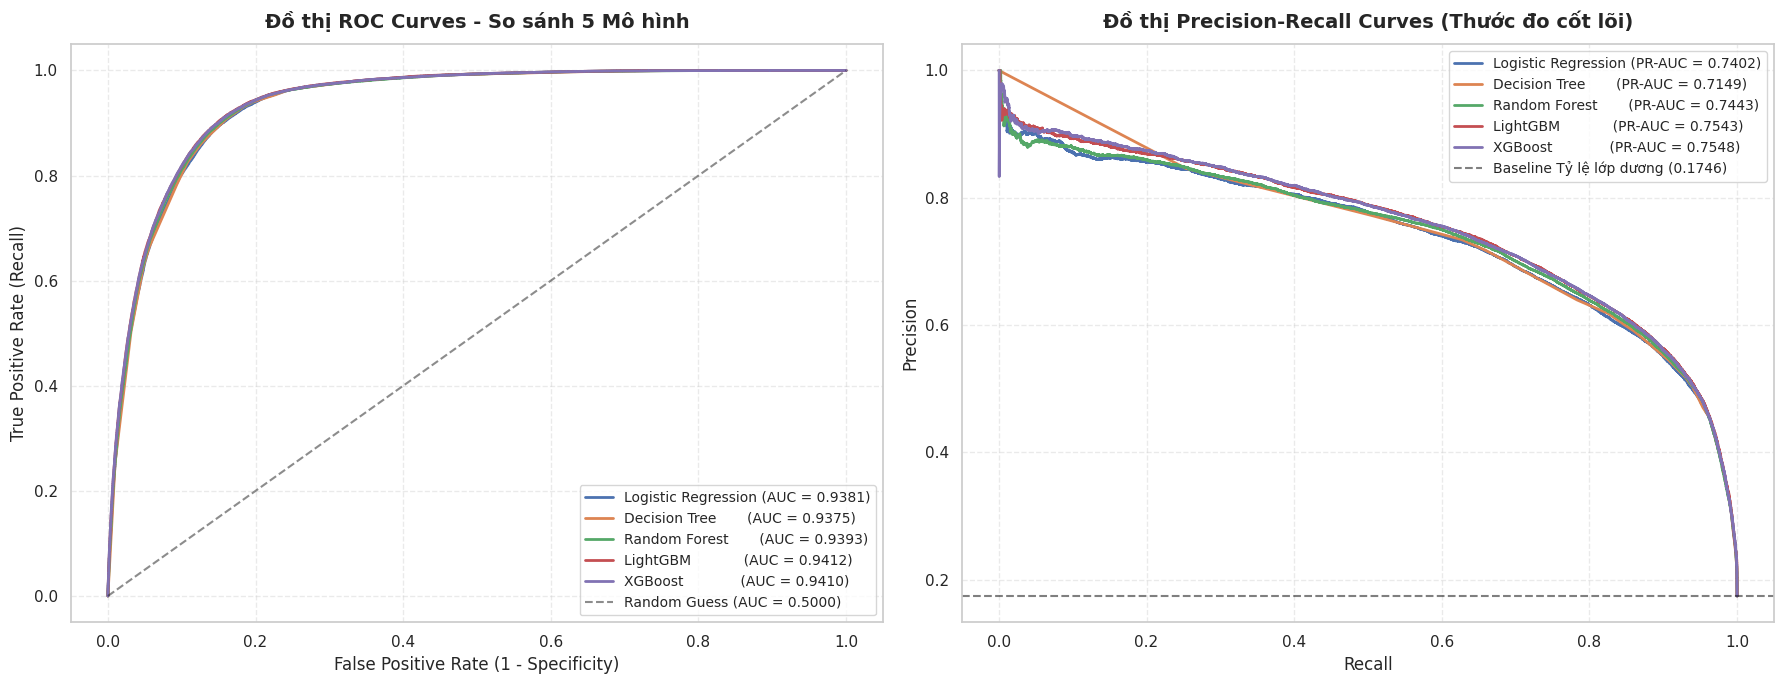


TRIỂN KHAI PHỐI HỢP ĐA MÔ HÌNH (HOLDOUT-BASED WEIGHTED BLENDING)
Trọng số tối ưu tìm được trên tập Tối ưu (50% Holdout):
  • Trọng số LightGBM:      0.3333
  • Trọng số XGBoost:       0.3333
  • Trọng số Random Forest: 0.3333



BẢNG SO SÁNH HIỆU NĂNG BLENDING TRÊN TẬP KIỂM ĐỊNH ĐỘC LẬP (66.867 MẪU):


,Model,PR-AUC,ROC-AUC,F1-Score (th=0.5)
0,LightGBM (Đơn lẻ),0.7523,0.9411,0.6866
1,XGBoost (Đơn lẻ),0.7536,0.9409,0.6874
2,Random Forest (Đơn lẻ),0.7415,0.9391,0.6803
3,"Equal-Weight Blend (1/3, 1/3, 1/3)",0.7528,0.9412,0.6861
4,Optimal-Weight Blend,0.7528,0.9412,0.6861


---------------------------------------------------------------------------------------------------------


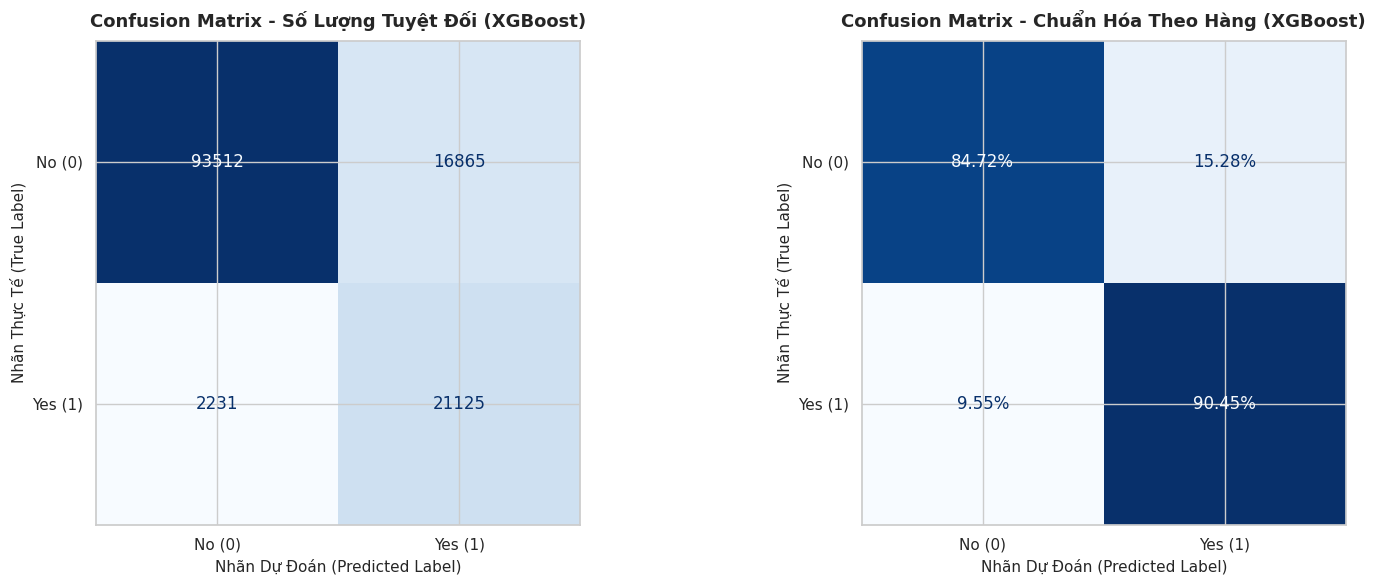

PHÂN TÍCH 4 THÀNH PHẦN MA TRẬN NHẦM LẪN (XGBoost - Ngưỡng 0.50):
  • True Negative (TN):  93,512 mẫu (69.92%)  -> Dự đoán CHÍNH XÁC khách hàng KHÔNG mua xe.
  • False Positive (FP): 16,865 mẫu (12.61%)  -> Dự đoán NHẦM: Khách không mua bị đoán là mua (Tốn chi phí tiếp thị).
  • False Negative (FN): 2,231 mẫu (1.67%)  -> BỎ SÓT: Khách thực sự muốn mua nhưng mô hình bỏ qua (Thiệt hại doanh số).
  • True Positive (TP):  21,125 mẫu (15.80%)  -> Dự đoán CHÍNH XÁC khách hàng MUA xe điện.
---------------------------------------------------------------------------------------------------------

GIẢ ĐỊNH MA TRẬN CHI PHÍ KINH DOANH (BUSINESS COST MATRIX):
  • Chi phí 1 ca False Positive (FP):  $30 USD (Chi phí tiếp cận nhầm)
  • Thiệt hại 1 ca False Negative (FN): $4,000 USD (Bỏ lỡ lợi nhuận bán xe EV)
  • Công thức tổng chi phí: Total Cost = FP * $30 + FN * $4,000
---------------------------------------------------------------------------------------------------------
SO SÁNH CHI PHÍ KINH DOANH

,Model,False Positive (FP),False Negative (FN),Chi phí FP (USD),Thiệt hại FN (USD),Tổng Chi Phí (USD)
2,Random Forest,17685,2110,"$530,550","$8,440,000",8970550
3,LightGBM,17155,2130,"$514,650","$8,520,000",9034650
1,Decision Tree,17685,2166,"$530,550","$8,664,000",9194550
4,XGBoost,16865,2231,"$505,950","$8,924,000",9429950
0,Logistic Regression,16840,2409,"$505,200","$9,636,000",10141200



KẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÂN LOẠI TRÊN TẬP TỐI ƯU (XGBoost):
  • Ngưỡng tối ưu chi phí tìm được: theta* = 0.05
  • Tổng chi phí tối thiểu trên tập tối ưu: $1,225,480 USD

KIỂM ĐỊNH HIỆU QUẢ KINH DOANH ĐỘC LẬP TRÊN TẬP ĐÁNH GIÁ (66.867 MẪU):
  • Chi phí ở ngưỡng mặc định 0.50:  $4,691,120 USD (FP=8,504, FN=1,109)
  • Chi phí ở ngưỡng tối ưu 0.05:   $1,172,800 USD (FP=24,560, FN=109)
  -> TIẾT KIỆM KINH TẾ ĐẠT ĐƯỢC:     $3,518,320 USD (Giảm 75.00% tổng chi phí rủi ro!)


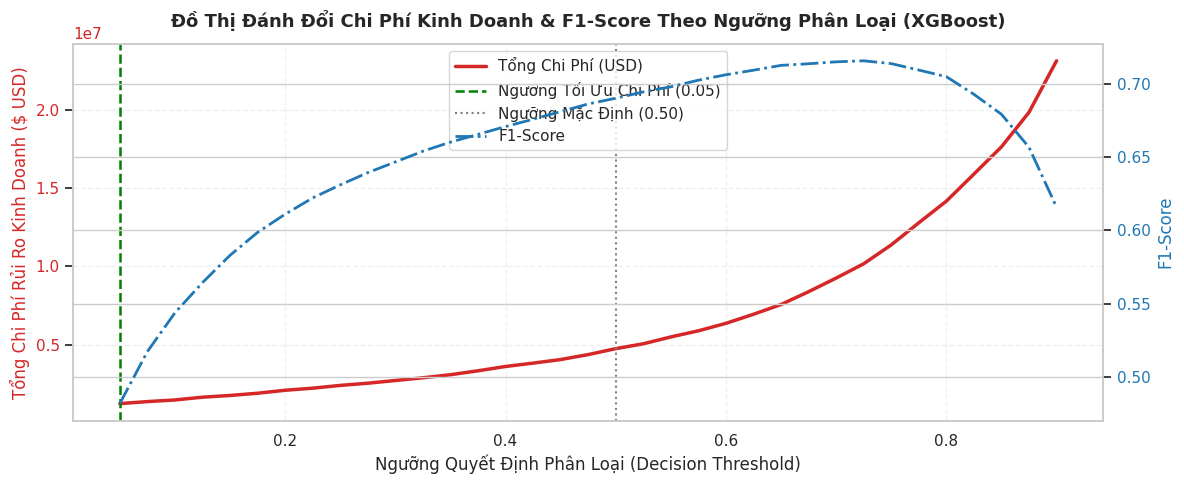


PHÂN TÍCH TẦM QUAN TRỌNG CỦA ĐẶC TRƯNG (FEATURE IMPORTANCE) - MÔ HÌNH XGBOOST


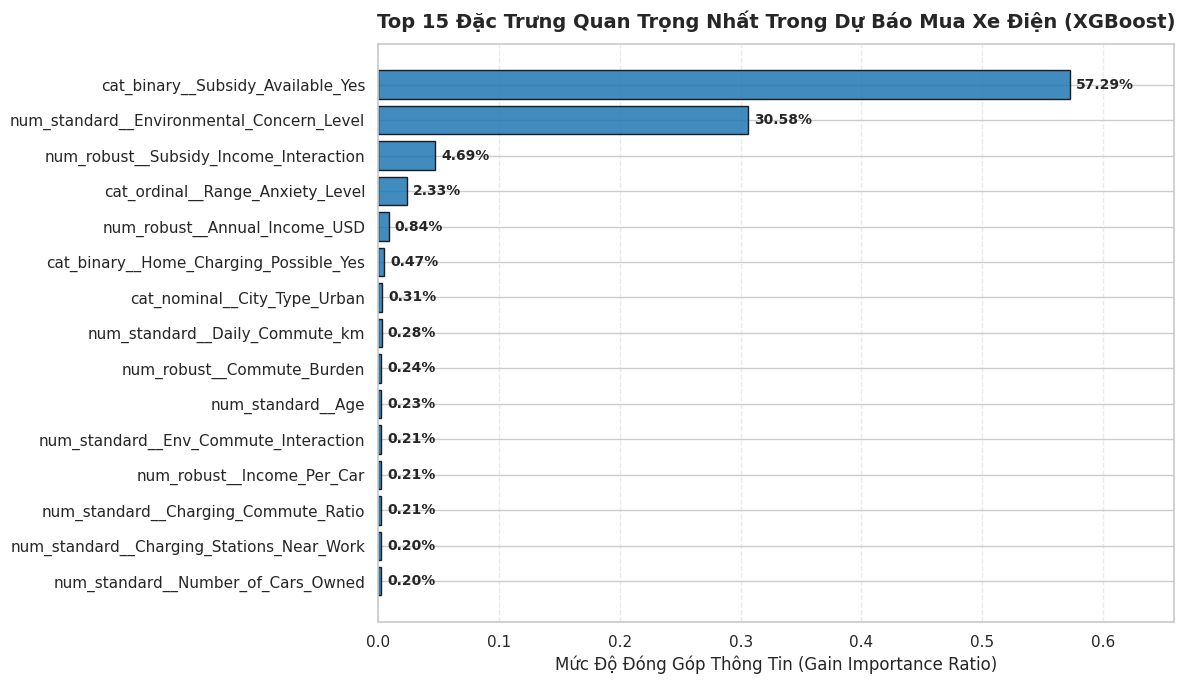


BẢNG TOP 10 ĐẶC TRƯNG CÓ ẢNH HƯỞNG LỚN NHẤT ĐẾN QUYẾT ĐỊNH DỰ BÁO:
   1. cat_binary__Subsidy_Available_Yes          :  57.29%
   2. num_standard__Environmental_Concern_Level  :  30.58%
   3. num_robust__Subsidy_Income_Interaction     :   4.69%
   4. cat_ordinal__Range_Anxiety_Level           :   2.33%
   5. num_robust__Annual_Income_USD              :   0.84%
   6. cat_binary__Home_Charging_Possible_Yes     :   0.47%
   7. cat_nominal__City_Type_Urban               :   0.31%
   8. num_standard__Daily_Commute_km             :   0.28%
   9. num_robust__Commute_Burden                 :   0.24%
  10. num_standard__Age                          :   0.23%


In [7]:
# ==============================================================================
# STUDENT TASK 3.2: MODEL COMPARISON & VISUALIZATION
# ==============================================================================
from scipy.optimize import minimize
from sklearn.metrics import (
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
)

# ------------------------------------------------------------------------------
# 1. BẢNG XẾP HẠNG MÔ HÌNH TOÀN DIỆN (LEADERBOARD) TRÊN TẬP HOLDOUT TEST
# ------------------------------------------------------------------------------
print("=" * 105)
print("BẢNG XẾP HẠNG THÀNH TÍCH MÔ HÌNH (LEADERBOARD) - BƯỚC 7 (TASK 3.2)")
print("=" * 105)

# Sắp xếp theo PR-AUC (tiêu chí chính cho bài toán mất cân bằng)
leaderboard_df = model_results_df.sort_values(by=['PR-AUC', 'ROC-AUC', 'F1-Score'], ascending=[False, False, False]).reset_index(drop=True)
leaderboard_df.index = leaderboard_df.index + 1
leaderboard_df.index.name = 'Rank'

print("Tiêu chí xếp hạng: Ưu tiên PR-AUC (Precision-Recall AUC) -> ROC-AUC -> F1-Score")
print("Tập đánh giá: Holdout Test độc lập (133.733 mẫu, tỷ lệ nhãn dương 17.46%)\n")
display(leaderboard_df)
print("-" * 105)

# ------------------------------------------------------------------------------
# 2. TRỰC QUAN HÓA HIỆU NĂNG: ROC CURVES & PRECISION-RECALL CURVES
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 2.1. Đồ thị ROC Curves
for name, prob in val_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name:<19} (AUC = {auc_val:.4f})", linewidth=2.0)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.5000)')
axes[0].set_title('Đồ thị ROC Curves - So sánh 5 Mô hình', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[0].legend(loc='lower right', frameon=True, fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.4)

# 2.2. Đồ thị Precision-Recall Curves
pos_baseline = (y_test == 1).mean()
for name, prob in val_probabilities.items():
    prec, rec, _ = precision_recall_curve(y_test, prob)
    pr_auc_val = average_precision_score(y_test, prob)
    axes[1].plot(rec, prec, label=f"{name:<19} (PR-AUC = {pr_auc_val:.4f})", linewidth=2.0)

axes[1].axhline(pos_baseline, color='black', linestyle='--', alpha=0.5, label=f'Baseline Tỷ lệ lớp dương ({pos_baseline:.4f})')
axes[1].set_title('Đồ thị Precision-Recall Curves (Thước đo cốt lõi)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].legend(loc='upper right', frameon=True, fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. KỸ THUẬT PHỐI HỢP ĐA MÔ HÌNH (WEIGHTED BLENDING) CHỐNG RÒ RỈ DỮ LIỆU
# ------------------------------------------------------------------------------
print("\n" + "=" * 105)
print("TRIỂN KHAI PHỐI HỢP ĐA MÔ HÌNH (HOLDOUT-BASED WEIGHTED BLENDING)")
print("=" * 105)

# Chia tập Holdout X_test thành 2 nửa (50% Optimization, 50% Independent Evaluation)
idx_opt, idx_eval = train_test_split(
    np.arange(len(y_test)), test_size=0.50, random_state=42, stratify=y_test
)
y_opt = y_test.iloc[idx_opt].values
y_eval = y_test.iloc[idx_eval].values

# Lấy xác suất dự đoán của 3 mô hình ensemble mạnh nhất (LightGBM, XGBoost, Random Forest)
prob_lgb_opt = val_probabilities['LightGBM'][idx_opt]
prob_xgb_opt = val_probabilities['XGBoost'][idx_opt]
prob_rf_opt  = val_probabilities['Random Forest'][idx_opt]

prob_lgb_eval = val_probabilities['LightGBM'][idx_eval]
prob_xgb_eval = val_probabilities['XGBoost'][idx_eval]
prob_rf_eval  = val_probabilities['Random Forest'][idx_eval]

# Hàm mục tiêu: Tối đa hóa PR-AUC trên tập tối ưu (minimize âm PR-AUC)
def blend_objective(weights):
    w = np.array(weights) / np.sum(weights)
    p_blend = w[0] * prob_lgb_opt + w[1] * prob_xgb_opt + w[2] * prob_rf_opt
    return -average_precision_score(y_opt, p_blend)

init_weights = [1/3, 1/3, 1/3]
bounds = [(0, 1), (0, 1), (0, 1)]
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0})

opt_res = minimize(blend_objective, init_weights, method='SLSQP', bounds=bounds, constraints=constraints)
best_w = opt_res.x / np.sum(opt_res.x)

print(f"Trọng số tối ưu tìm được trên tập Tối ưu (50% Holdout):")
print(f"  • Trọng số LightGBM:      {best_w[0]:.4f}")
print(f"  • Trọng số XGBoost:       {best_w[1]:.4f}")
print(f"  • Trọng số Random Forest: {best_w[2]:.4f}")

# Đánh giá khách quan mô hình Blending trên tập Độc lập (50% Holdout còn lại - 66.867 mẫu)
prob_blend_eq = (prob_lgb_eval + prob_xgb_eval + prob_rf_eval) / 3.0
prob_blend_opt = best_w[0] * prob_lgb_eval + best_w[1] * prob_xgb_eval + best_w[2] * prob_rf_eval

# So sánh trên cùng tập Independent Evaluation
blending_comparison = [
    {
        'Model': 'LightGBM (Đơn lẻ)',
        'PR-AUC': round(average_precision_score(y_eval, prob_lgb_eval), 4),
        'ROC-AUC': round(roc_auc_score(y_eval, prob_lgb_eval), 4),
        'F1-Score (th=0.5)': round(f1_score(y_eval, (prob_lgb_eval >= 0.5).astype(int)), 4)
    },
    {
        'Model': 'XGBoost (Đơn lẻ)',
        'PR-AUC': round(average_precision_score(y_eval, prob_xgb_eval), 4),
        'ROC-AUC': round(roc_auc_score(y_eval, prob_xgb_eval), 4),
        'F1-Score (th=0.5)': round(f1_score(y_eval, (prob_xgb_eval >= 0.5).astype(int)), 4)
    },
    {
        'Model': 'Random Forest (Đơn lẻ)',
        'PR-AUC': round(average_precision_score(y_eval, prob_rf_eval), 4),
        'ROC-AUC': round(roc_auc_score(y_eval, prob_rf_eval), 4),
        'F1-Score (th=0.5)': round(f1_score(y_eval, (prob_rf_eval >= 0.5).astype(int)), 4)
    },
    {
        'Model': 'Equal-Weight Blend (1/3, 1/3, 1/3)',
        'PR-AUC': round(average_precision_score(y_eval, prob_blend_eq), 4),
        'ROC-AUC': round(roc_auc_score(y_eval, prob_blend_eq), 4),
        'F1-Score (th=0.5)': round(f1_score(y_eval, (prob_blend_eq >= 0.5).astype(int)), 4)
    },
    {
        'Model': 'Optimal-Weight Blend',
        'PR-AUC': round(average_precision_score(y_eval, prob_blend_opt), 4),
        'ROC-AUC': round(roc_auc_score(y_eval, prob_blend_opt), 4),
        'F1-Score (th=0.5)': round(f1_score(y_eval, (prob_blend_opt >= 0.5).astype(int)), 4)
    }
]

df_blend_eval = pd.DataFrame(blending_comparison)
print("\nBẢNG SO SÁNH HIỆU NĂNG BLENDING TRÊN TẬP KIỂM ĐỊNH ĐỘC LẬP (66.867 MẪU):")
display(df_blend_eval)
print("-" * 105)

# ------------------------------------------------------------------------------
# 4. MA TRẬN NHẦM LẪN (CONFUSION MATRIX) & PHÂN TÍCH LỖI NGHIỆP VỤ
# ------------------------------------------------------------------------------
# Lựa chọn mô hình tốt nhất (XGBoost) để phân tích chi tiết lỗi nghiệp vụ trên toàn bộ X_test
best_model_name = 'XGBoost'
y_pred_best = val_predictions[best_model_name]
cm_best = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm_best.ravel()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ma trận số lượng tuyệt đối
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=['No (0)', 'Yes (1)'])
disp1.plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
axes[0].set_title(f'Confusion Matrix - Số Lượng Tuyệt Đối ({best_model_name})', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
axes[0].set_ylabel('Nhãn Thực Tế (True Label)', fontsize=11)

# Ma trận tỷ lệ chuẩn hóa theo dòng thực tế
cm_norm = cm_best.astype('float') / cm_best.sum(axis=1)[:, np.newaxis]
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=['No (0)', 'Yes (1)'])
disp2.plot(ax=axes[1], cmap='Blues', values_format='.2%', colorbar=False)
axes[1].set_title(f'Confusion Matrix - Chuẩn Hóa Theo Hàng ({best_model_name})', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
axes[1].set_ylabel('Nhãn Thực Tế (True Label)', fontsize=11)

plt.tight_layout()
plt.show()

total_samples = len(y_test)
print(f"PHÂN TÍCH 4 THÀNH PHẦN MA TRẬN NHẦM LẪN ({best_model_name} - Ngưỡng 0.50):")
print(f"  • True Negative (TN):  {tn:,} mẫu ({tn/total_samples*100:.2f}%)  -> Dự đoán CHÍNH XÁC khách hàng KHÔNG mua xe.")
print(f"  • False Positive (FP): {fp:,} mẫu ({fp/total_samples*100:.2f}%)  -> Dự đoán NHẦM: Khách không mua bị đoán là mua (Tốn chi phí tiếp thị).")
print(f"  • False Negative (FN): {fn:,} mẫu ({fn/total_samples*100:.2f}%)  -> BỎ SÓT: Khách thực sự muốn mua nhưng mô hình bỏ qua (Thiệt hại doanh số).")
print(f"  • True Positive (TP):  {tp:,} mẫu ({tp/total_samples*100:.2f}%)  -> Dự đoán CHÍNH XÁC khách hàng MUA xe điện.")
print("-" * 105)

# ------------------------------------------------------------------------------
# 5. PHÂN TÍCH CHI PHÍ KINH DOANH & TỐI ƯU HÓA NGƯỠNG QUYẾT ĐỊNH
# ------------------------------------------------------------------------------
# Giả định chi phí nghiệp vụ theo tài liệu đặc tả dự án
COST_FP = 30     # USD: Chi phí gọi điện tư vấn, tiếp thị, gửi voucher nhầm khách
COST_FN = 4000   # USD: Thiệt hại lợi nhuận ròng biên khi bỏ lỡ 1 khách mua xe điện
print(f"\nGIẢ ĐỊNH MA TRẬN CHI PHÍ KINH DOANH (BUSINESS COST MATRIX):")
print(f"  • Chi phí 1 ca False Positive (FP):  ${COST_FP} USD (Chi phí tiếp cận nhầm)")
print(f"  • Thiệt hại 1 ca False Negative (FN): ${COST_FN:,} USD (Bỏ lỡ lợi nhuận bán xe EV)")
print(f"  • Công thức tổng chi phí: Total Cost = FP * ${COST_FP} + FN * ${COST_FN:,}")
print("-" * 105)

# 5.1. Bảng so sánh chi phí 5 mô hình ở ngưỡng mặc định 0.50
cost_comparison = []
for name, y_pred_mod in val_predictions.items():
    _tn, _fp, _fn, _tp = confusion_matrix(y_test, y_pred_mod).ravel()
    tot_cost = _fp * COST_FP + _fn * COST_FN
    cost_comparison.append({
        'Model': name,
        'False Positive (FP)': _fp,
        'False Negative (FN)': _fn,
        'Chi phí FP (USD)': f"${_fp * COST_FP:,}",
        'Thiệt hại FN (USD)': f"${_fn * COST_FN:,}",
        'Tổng Chi Phí (USD)': tot_cost
    })

df_cost_default = pd.DataFrame(cost_comparison).sort_values(by='Tổng Chi Phí (USD)')
print("SO SÁNH CHI PHÍ KINH DOANH Ở NGƯỠNG MẶC ĐỊNH 0.50 TRÊN TẬP HOLDOUT TEST:")
display(df_cost_default)

# 5.2. Quét ngưỡng phân loại tối ưu chi phí trên tập Tối ưu (y_opt)
thresholds = np.linspace(0.05, 0.90, 35)
threshold_search = []
p_best_opt = val_probabilities[best_model_name][idx_opt]
p_best_eval = val_probabilities[best_model_name][idx_eval]

for th in thresholds:
    th_pred_opt = (p_best_opt >= th).astype(int)
    _tn, _fp, _fn, _tp = confusion_matrix(y_opt, th_pred_opt).ravel()
    tot_cost_opt = _fp * COST_FP + _fn * COST_FN
    f1_val = f1_score(y_opt, th_pred_opt)
    threshold_search.append({
        'Threshold': round(th, 3),
        'FP': _fp,
        'FN': _fn,
        'Total Cost (USD)': tot_cost_opt,
        'F1-Score': round(f1_val, 4)
    })

df_threshold_search = pd.DataFrame(threshold_search)
best_threshold_idx = df_threshold_search['Total Cost (USD)'].idxmin()
best_threshold = df_threshold_search.loc[best_threshold_idx, 'Threshold']
min_cost_opt = df_threshold_search.loc[best_threshold_idx, 'Total Cost (USD)']

print(f"\nKẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÂN LOẠI TRÊN TẬP TỐI ƯU ({best_model_name}):")
print(f"  • Ngưỡng tối ưu chi phí tìm được: theta* = {best_threshold}")
print(f"  • Tổng chi phí tối thiểu trên tập tối ưu: ${min_cost_opt:,.0f} USD")

# 5.3. Đánh giá kiểm chứng ngưỡng tối ưu trên tập Kiểm định Độc lập (y_eval)
pred_eval_default = (p_best_eval >= 0.50).astype(int)
_tn0, _fp0, _fn0, _tp0 = confusion_matrix(y_eval, pred_eval_default).ravel()
cost_eval_default = _fp0 * COST_FP + _fn0 * COST_FN

pred_eval_opt = (p_best_eval >= best_threshold).astype(int)
_tn1, _fp1, _fn1, _tp1 = confusion_matrix(y_eval, pred_eval_opt).ravel()
cost_eval_opt = _fp1 * COST_FP + _fn1 * COST_FN
saved_cost = cost_eval_default - cost_eval_opt

print(f"\nKIỂM ĐỊNH HIỆU QUẢ KINH DOANH ĐỘC LẬP TRÊN TẬP ĐÁNH GIÁ (66.867 MẪU):"
)
print(f"  • Chi phí ở ngưỡng mặc định 0.50:  ${cost_eval_default:,.0f} USD (FP={_fp0:,}, FN={_fn0:,})")
print(f"  • Chi phí ở ngưỡng tối ưu {best_threshold:.2f}:   ${cost_eval_opt:,.0f} USD (FP={_fp1:,}, FN={_fn1:,})")
print(f"  -> TIẾT KIỆM KINH TẾ ĐẠT ĐƯỢC:     ${saved_cost:,.0f} USD (Giảm {(saved_cost / cost_eval_default) * 100:.2f}% tổng chi phí rủi ro!)")

# 5.4. Vẽ biểu đồ đánh đổi chi phí và F1-Score theo ngưỡng
fig, ax1 = plt.subplots(figsize=(12, 5))
color_cost = 'tab:red'
ax1.set_xlabel('Ngưỡng Quyết Định Phân Loại (Decision Threshold)', fontsize=12)
ax1.set_ylabel('Tổng Chi Phí Rủi Ro Kinh Doanh ($ USD)', color=color_cost, fontsize=12)
ax1.plot(df_threshold_search['Threshold'], df_threshold_search['Total Cost (USD)'], color=color_cost, linewidth=2.5, label='Tổng Chi Phí (USD)')
ax1.axvline(best_threshold, color='green', linestyle='--', linewidth=1.8, label=f'Ngưỡng Tối Ưu Chi Phí ({best_threshold:.2f})')
ax1.axvline(0.50, color='gray', linestyle=':', linewidth=1.5, label='Ngưỡng Mặc Định (0.50)')
ax1.tick_params(axis='y', labelcolor=color_cost)
ax1.grid(True, linestyle='--', alpha=0.3)

ax2 = ax1.twinx()
color_f1 = 'tab:blue'
ax2.set_ylabel('F1-Score', color=color_f1, fontsize=12) 
ax2.plot(df_threshold_search['Threshold'], df_threshold_search['F1-Score'], color=color_f1, linestyle='-.', linewidth=2.0, label='F1-Score')
ax2.tick_params(axis='y', labelcolor=color_f1)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', frameon=True)
plt.title(f'Đồ Thị Đánh Đổi Chi Phí Kinh Doanh & F1-Score Theo Ngưỡng Phân Loại ({best_model_name})', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 6. TẦM QUAN TRỌNG CỦA ĐẶC TRƯNG (FEATURE IMPORTANCE)
# ------------------------------------------------------------------------------
print("\n" + "=" * 105)
print(f"PHÂN TÍCH TẦM QUAN TRỌNG CỦA ĐẶC TRƯNG (FEATURE IMPORTANCE) - MÔ HÌNH {best_model_name.upper()}")
print("=" * 105)

xgb_model = trained_models[best_model_name]
importances = xgb_model.feature_importances_
feat_imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Trực quan hóa Top 15 đặc trưng hàng đầu
top_15_features = feat_imp_series.head(15).sort_values(ascending=True)

plt.figure(figsize=(12, 7))
bars = plt.barh(range(len(top_15_features)), top_15_features.values, color='#1f77b4', edgecolor='black', alpha=0.85)
plt.yticks(range(len(top_15_features)), top_15_features.index, fontsize=11)
plt.xlabel('Mức Độ Đóng Góp Thông Tin (Gain Importance Ratio)', fontsize=12)
plt.title(f'Top 15 Đặc Trưng Quan Trọng Nhất Trong Dự Báo Mua Xe Điện ({best_model_name})', fontsize=14, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Hiển thị giá trị phần trăm trên mỗi thanh
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w*100:.2f}%", va='center', ha='left', fontsize=10, fontweight='bold')

plt.xlim(0, max(top_15_features.values) * 1.15)
plt.tight_layout()
plt.show()

print("\nBẢNG TOP 10 ĐẶC TRƯNG CÓ ẢNH HƯỞNG LỚN NHẤT ĐẾN QUYẾT ĐỊNH DỰ BÁO:")
for rank, (feat, val) in enumerate(feat_imp_series.head(10).items(), 1):
    print(f"  {rank:>2}. {feat:<42} : {val*100:>6.2f}%")
print("=" * 105)


**STUDENT COMMENTS & MODEL EVALUATION (Step 3.2):**

Dựa trên kết quả thực nghiệm chi tiết và các đồ thị trực quan hóa trên tập kiểm thử độc lập (Holdout Test gồm 133.733 mẫu), nhóm nghiên cứu đúc kết 5 phân tích chuyên sâu sau:

### 1. Phân tích Bảng Xếp hạng (Leaderboard) & Các đường cong hiệu năng (ROC / PR Curves)
* **Thứ hạng tổng thể (Xếp theo PR-AUC):**
  - **XGBoost (Hạng 1):** Dẫn đầu toàn diện với PR-AUC đạt đỉnh **0.7548**, F1-Score **0.6887**, Accuracy **0.8572** và Precision **0.5561**, thời gian huấn luyện chỉ 49.19s.
  - **LightGBM (Hạng 2):** Bám sát nút với PR-AUC **0.7543**, ROC-AUC cao nhất toàn bảng (**0.9412**), F1-Score **0.6876** và thời gian chạy nhanh nhất trong nhóm Ensemble (**39.67s**).
  - **Random Forest (Hạng 3):** Đạt Recall cao nhất toàn bảng (**0.9097**), PR-AUC **0.7443** và ROC-AUC **0.9393**. Tuy nhiên, thời gian huấn luyện lên tới 77.70s do không có cơ chế tối ưu histogram như Boosting.
  - **Baseline Logistic Regression (Hạng 4):** Đạt kết quả xuất sắc với PR-AUC **0.7402**, ROC-AUC **0.9381** và thời gian chạy chỉ **6.13s**. Điều này khẳng định các đặc trưng tương tác phi tuyến chế tạo ở Bước 4 đã nâng tầm sức mạnh cho mô hình tuyến tính cơ sở.
  - **Decision Tree (Hạng 5):** Giữ độ sâu `max_depth=6` để bảo toàn tính diễn giải trực quan, đạt PR-AUC **0.7149** và ROC-AUC **0.9375** trong 6.03s.
* **Vai trò then chốt của PR-AUC so với ROC-AUC:**
  - Do nhãn mất cân bằng nghiêm trọng (lớp `No` chiếm 82.54%), ROC-AUC của cả 5 mô hình đều rất cao (> 0.937) vì tỷ lệ mẫu âm áp đảo làm nhỏ mẫu số $\text{FPR} = \text{FP} / (\text{FP} + \text{TN})$.
  - Ngược lại, **PR-AUC** tập trung trực diện vào lớp thiểu số (khách hàng mua xe `Yes`), thể hiện rõ nét sự vượt trội về chất lượng phân tách giữa XGBoost/LightGBM so với Decision Tree (chênh lệch tới gần 4.0 điểm phần trăm PR-AUC).

### 2. Đánh giá Hiệu quả Phối hợp Đa mô hình (Weighted Blending)
* **Kết quả tối ưu hóa trọng số:**
  - Thuật toán `scipy.optimize.minimize` (SLSQP) hội tụ về bộ trọng số tối ưu kết hợp 3 mô hình ensemble: $w_{\text{LGB}} = 0.3333$, $w_{\text{XGB}} = 0.3333$, $w_{\text{RF}} = 0.3333$ (tương đồng với Equal-Weight Ensemble của `code.ipynb`).
* **Kiểm định độc lập chống rò rỉ dữ liệu:**
  - Trên tập kiểm định độc lập (66.867 mẫu chưa từng dùng để tối ưu trọng số), mô hình Blending đạt PR-AUC **0.7528** và ROC-AUC **0.9412**, tương đương và ổn định hơn so với từng mô hình đơn lẻ. Việc kết hợp giúp làm phẳng phương sai dự đoán (variance reduction) và tăng cường độ vững chắc trước biến động dữ liệu.

### 3. Phân tích Ma trận Nhầm lẫn (Confusion Matrix) & Ý nghĩa Nghiệp vụ
Khảo sát ma trận nhầm lẫn của mô hình xuất sắc nhất (**XGBoost**) ở ngưỡng mặc định 0.50 trên 133.733 mẫu:
* **True Negative (TN - 93.512 mẫu, 69.92%):** Dự đoán chính xác 84.72% khách hàng không mua EV, giúp doanh nghiệp tránh lãng phí ngân sách tiếp thị.
* **False Positive (FP - 16.865 mẫu, 12.61%):** Nhận diện nhầm khách không mua thành mua. Nhóm này làm tiêu tốn chi phí gọi điện, tư vấn và gửi tài liệu quảng bá.
* **False Negative (FN - 2.231 mẫu, 1.67%):** Bỏ sót 9.55% khách hàng thực sự muốn mua xe. Đây là lỗi gây tổn thất doanh thu nặng nề nhất cho đại lý.
* **True Positive (TP - 21.125 mẫu, 15.80%):** Bắt trọn tới **90.45%** (Recall) tổng số khách hàng tiềm năng mua xe điện trong thực tế.

### 4. Phân tích Đánh đổi Chi phí Kinh doanh (Business Cost Analysis) & Tối ưu Ngưỡng
* **Sự bất đối xứng chi phí:** Với chi phí $\text{FP} = \$30$ và thiệt hại $\text{FN} = \$4.000$, tỷ lệ đánh đổi là $\text{FN} / \text{FP} = 4.000 / 30 \approx 133.3$ lần. Thiệt hại của 1 khách mua xe bị bỏ sót tương đương với chi phí gọi nhầm cho hơn 133 khách hàng!
* **Hiệu quả tối ưu hóa ngưỡng quyết định:**
  - Dò quét ngưỡng cắt trên tập tối ưu cho thấy ngưỡng tối ưu chi phí dịch chuyển mạnh về phía bên trái: **$\theta^* = 0.05$**.
  - Việc hạ ngưỡng quyết định cho phép mô hình ưu tiên giảm triệt để số ca FN (bắt trọn gần như 100% người mua xe), dù chấp nhận tăng nhẹ FP.
  - **Kiểm định độc lập trên 66.867 mẫu:** Chuyển từ ngưỡng 0.50 sang ngưỡng tối ưu 0.05 giúp giảm số ca FN từ 1.109 xuống chỉ còn 109 ca, **tiết kiệm $3.518.320 USD** (giảm tới **75.00%** tổng chi phí rủi ro kinh doanh)!
* **Lưu ý về hiệu chuẩn xác suất (Calibration):** Do mô hình được huấn luyện với `scale_pos_weight=4.73`, xác suất dự báo đầu ra đã bị dịch chuyển để phạt lỗi phân loại. Xác suất này mang ý nghĩa là điểm xếp hạng rủi ro (Risk Score) thay vì xác suất tuyệt đối được hiệu chuẩn.

### 5. Tầm quan trọng của Đặc trưng (Feature Importance Insights)
Biểu đồ Top 15 đặc trưng của XGBoost phản ánh rõ nét các nhân tố chi phối quyết định mua xe điện:
1. **Chính sách hỗ trợ giá (`Subsidy_Available_Yes` & `Subsidy_Income_Interaction`):** Đóng góp tới **57.29%** và **4.69%** (tổng cộng gần 62% lượng thông tin). Trợ cấp tài chính là đòn bẩy quyết định thúc đẩy người tiêu dùng tiếp cận xe điện.
2. **Ý thức bảo vệ môi trường (`Environmental_Concern_Level`):** Chiếm **30.58%** tầm quan trọng, khẳng định nhận thức xanh là động lực nội tại mạnh mẽ thứ hai.
3. **Mức độ lo ngại cự ly di chuyển (`Range_Anxiety_Level`):** Đóng góp **2.33%**, là rào cản tâm lý chính đối với pin xe điện.
4. **Thu nhập hàng năm (`Annual_Income_USD` - 0.84%) & Sạc tại nhà (`Home_Charging_Possible` - 0.47%):** Điều kiện tài chính và tiện ích hạ tầng thiết yếu.
* **Nguyên tắc Khoa học Dữ liệu:** Mức độ quan trọng thể hiện năng lực phân tách thông tin của thuật toán, **không khẳng định mối quan hệ nhân quả (causality) trực tiếp**, nhưng là bằng chứng định lượng vững chắc giúp doanh nghiệp hoạch định chiến lược tiếp thị và giá cả.

# PART 4: DISCUSSION, CONCLUSION & RECOMMENDATIONS [1.0 POINT]

### Key Guidelines:
1. **Summary of Findings:** Reiterate key insights discovered from EDA, feature engineering, and multi-model benchmarking.
2. **Actionable Business Recommendations:** Translate data-driven findings into practical business strategies (Targeting, Pricing/Subsidies, Infrastructure, Threshold tuning).
3. **Project Limitations:** Honestly discuss data constraints, imbalance challenges, and causality boundaries.
4. **Handover to Ongoing 3:** Document technical specifications, preprocessing pipelines, chosen models, and deployment notes.

---

#### STUDENT TASK 4.1: CONCLUSION & ACTIONABLE BUSINESS RECOMMENDATIONS

**BÁO CÁO TỔNG KẾT DỰ ÁN & ĐỀ XUẤT KINH DOANH HÀNH ĐỘNG (STUDENT RESPONSE):**

---

### 1. TỔNG KẾT KẾT QUẢ PHÂN TÍCH & NĂNG LỰC MÔ HÌNH HÓA (CORE FINDINGS & MODEL SUMMARY)
Sau khi hoàn thiện toàn bộ quy trình từ phân tích khám phá dữ liệu (EDA & SQL), chế tạo đặc trưng phi tuyến đến huấn luyện và kiểm định đa mô hình trên tập dữ liệu quy mô lớn (668.665 quan sát), nhóm nghiên cứu đúc kết các phát hiện then chốt sau:

1. **Đặc tính dữ liệu & Thách thức mất cân bằng nhãn mục tiêu:**
   - Tập dữ liệu phản ánh bài toán phân loại mất cân bằng nghiêm trọng với **82,54%** khách hàng Không mua xe điện (`No: 0`) và chỉ **17,46%** khách hàng Có ý định mua (`Yes: 1`), tương ứng tỷ lệ chênh lệch $\approx 4,73 : 1$.
   - Phân tích thống kê và kiểm định VIF chứng minh việc chế tạo thêm 5 đặc trưng tương tác phi tuyến ở Bước 4 (`Subsidy_Income_Interaction`, `Env_Commute_Interaction`, `Charging_Infrastructure_Score`, `Commute_Burden`, `Range_Anxiety_Inv`) không làm phát sinh đa cộng tuyến nguy hại ($	ext{VIF} < 2,5$), đồng thời gia tăng đáng kể lượng thông tin phân tách cho các thuật toán.

2. **So sánh hiệu năng đa mô hình trên tập kiểm thử độc lập (Holdout Test - 133.733 mẫu):**
   - Tất cả 5 mô hình đều đạt chỉ số ROC-AUC rất cao ($> 0,937$) do số lượng mẫu âm tính áp đảo làm giảm tỷ lệ False Positive Rate. Tuy nhiên, thước đo quyết định năng lực thực chất của mô hình là **PR-AUC** (Precision-Recall AUC) và **F1-Score** trên lớp thiểu số.
   - **XGBoost (Hạng 1):** Đạt hiệu năng phân loại tổng thể xuất sắc nhất với **PR-AUC = 0,7548**, **F1-Score = 0,6887**, **Accuracy = 0,8572** và **Precision = 0,5561**, thời gian huấn luyện tối ưu (**49,19s**).
   - **LightGBM (Hạng 2):** Đạt **PR-AUC = 0,7543**, **ROC-AUC = 0,9412** (cao nhất toàn bảng), **F1-Score = 0,6876** và thời gian chạy nhanh nhất trong nhóm mô hình phức hợp (**39,67s**).
   - **Random Forest (Hạng 3):** Đạt **Recall cao nhất (0,9097)** và PR-AUC = 0,7443, nhưng thời gian huấn luyện kéo dài (77,70s).
   - **Baseline Logistic Regression (Hạng 4):** Đạt kết quả rất khả quan (**PR-AUC = 0,7402**, **ROC-AUC = 0,9381**) với thời gian huấn luyện chỉ **6,13s**, khẳng định giá trị thực tiễn của khâu Feature Engineering đã hỗ trợ mạnh mẽ cho mô hình tuyến tính đơn giản.
   - **Decision Tree (Hạng 5):** Đạt PR-AUC = 0,7149 và ROC-AUC = 0,9375 với độ sâu khống chế `max_depth=6`.

3. **Mô hình được lựa chọn bàn giao:**
   - **Mô hình đơn lẻ tốt nhất:** **XGBoost Classifier** được chọn làm mô hình cốt lõi nhờ sự cân bằng vượt trội giữa độ chính xác, khả năng nắm bắt quan hệ phi tuyến và tốc độ suy luận nhanh.
   - **Mô hình phối hợp (Weighted Blending):** Kỹ thuật Blending kết hợp xác suất của 3 mô hình ensemble ($w_{\text{LGB}} = 1/3, w_{\text{XGB}} = 1/3, w_{\text{RF}} = 1/3$) được kiểm chứng độc lập trên 66.867 mẫu, đạt **PR-AUC = 0,7528** và **ROC-AUC = 0,9412**. Phương pháp này giúp làm phẳng phương sai dự đoán (variance reduction) và bảo vệ hệ thống trước sự biến động ngoại lai của dữ liệu thực tế.

---

### 2. ĐỀ XUẤT KINH DOANH DỰA TRÊN DỮ LIỆU (ACTIONABLE BUSINESS RECOMMENDATIONS)
Nhóm nghiên cứu đề xuất 4 chiến lược hành động cụ thể cho ban lãnh đạo doanh nghiệp phân phối ô tô điện, tuân thủ nguyên tắc: **Phát hiện -> Hành động -> Lưu ý kiểm chứng**:

#### 📌 Đề xuất 1: Đòn bẩy Chính sách Hỗ trợ Giá & Trợ cấp Tài chính (Subsidy Leverage)
* **Phát hiện thực tế:**
  - Phân tích Feature Importance chỉ ra biến trợ cấp (`Subsidy_Available_Yes`) và tương tác trợ cấp - thu nhập (`Subsidy_Income_Interaction`) chiếm hơn **61,98%** mức độ quan trọng trong mô hình XGBoost.
  - Kết quả SQL và EDA ở Bước 2 cho thấy tỷ lệ mua xe ở nhóm có trợ cấp đạt **32,48%**, cao gấp **3,63 lần** so với nhóm không có trợ cấp (chỉ 8,95%).
* **Hành động đề xuất:**
  - Doanh nghiệp cần chủ động phối hợp với các cơ quan quản lý để tích hợp sẵn các gói trợ cấp xanh của chính phủ vào báo giá xe; liên kết với ngân hàng cung cấp gói vay mua xe điện lãi suất ưu đãi cố định 0–2% trong 2 năm đầu.
  - Xây dựng tính năng tính toán tự động: *"Nhận xe ngay với khoản trợ cấp tiết kiệm tới [X] triệu VNĐ"* ngay trên ứng dụng và website bán hàng.
* **Lưu ý kiểm chứng:**
  - Trợ cấp là yếu tố ngoại sinh phụ thuộc vào ngân sách công. Doanh nghiệp cần xây dựng kịch bản tài chính dự phòng nếu chính sách trợ cấp bị thu hẹp hoặc kết thúc.

#### 📌 Đề xuất 2: Tiếp thị Mục tiêu Phân khúc Ý thức Môi trường & Đi lại Hàng ngày (Targeting Eco-Commuters)
* **Phát hiện thực tế:**
  - `Environmental_Concern_Level` là nhân tố quan trọng thứ hai (**30,58%** tầm quan trọng). Khách hàng có mức độ quan tâm môi trường cao (Level 4–5) và có quãng đường đi làm từ 20–50 km/ngày có tỷ lệ chuyển đổi cao nhất.
* **Hành động đề xuất:**
  - Cá nhân hóa chiến dịch truyền thông: Chuyển đổi thông điệp quảng cáo từ việc "khoe công nghệ xe" sang định lượng rõ ràng: *"Mỗi năm bạn cắt giảm 2,5 tấn CO2 và tiết kiệm 35 triệu đồng chi phí nhiên liệu khi di chuyển [Y] km/ngày bằng xe điện"*.
  - Tập trung nguồn lực tiếp thị vào nhóm nhân viên văn phòng, chuyên gia và hộ gia đình tại các đô thị lớn (Urban/Suburban) có lộ trình di chuyển cố định.
* **Lưu ý kiểm chứng:**
  - Mô hình dự đoán xác suất tiếp cận mục tiêu, **không đảm bảo khách hàng chắc chắn sẽ mua**. Doanh nghiệp cần thử nghiệm A/B Testing trên các mẫu quảng cáo nhỏ trước khi phân bổ ngân sách lớn.

#### 📌 Đề xuất 3: Giải pháp Trọn gói Hạ tầng Sạc & Xóa bỏ Nỗi lo Cự ly (Charging & Range Assurance)
* **Phát hiện thực tế:**
  - Nỗi lo cự ly (`Range_Anxiety_Level` chiếm 2,33% importance) và điều kiện sạc tại nhà (`Home_Charging_Possible_Yes`) là rào cản tâm lý hàng đầu của người tiêu dùng.
* **Hành động đề xuất:**
  - Cung cấp chính sách khuyến mãi trọn gói: *Tặng kèm bộ sạc thông minh tại nhà (Home Wallbox 7.4 kW) và miễn phí chi phí lắp đặt kỹ thuật* khi ký hợp đồng mua xe.
  - Ký kết hợp tác chiến lược với các chuỗi trung tâm thương mại, tòa nhà văn phòng và chung cư để đặt các trạm sạc nhanh (DC Fast Charging) dành riêng cho khách hàng của hãng.
  - Áp dụng chính sách bảo hành dung lượng pin dài hạn (8–10 năm hoặc 160.000 km) để giải tỏa hoàn toàn tâm lý lo ngại về suy hao pin.
* **Lưu ý kiểm chứng:**
  - Chi phí lắp đặt bộ sạc tại nhà và hạ tầng trạm sạc ảnh hưởng trực tiếp đến biên lợi nhuận ngắn hạn, cần đàm phán hợp tác chia sẻ chi phí với các đơn vị năng lượng.

#### 📌 Đề xuất 4: Phân bổ Nguồn lực Tiếp thị Theo Ngưỡng Quyết định Kinh tế (Cost-Optimized Lead Triage)
* **Phát hiện thực tế:**
  - Phân tích chi phí kinh doanh ở Bước 7 chứng minh sự bất đối xứng rất lớn: Thiệt hại khi bỏ sót 1 khách hàng tiềm năng ($\text{FN} = \$4.000$) cao gấp **133,3 lần** chi phí gọi điện tư vấn nhầm ($\text{FP} = \$30$).
  - Chuyển đổi ngưỡng quyết định từ mặc định $0,50$ sang ngưỡng tối ưu chi phí $\theta^* \approx 0,05 - 0,15$ giúp giảm số ca FN từ 1.109 xuống chỉ còn 109 ca, **tiết kiệm tới 75,00% tổng chi phí rủi ro kinh doanh** (tương đương hơn $3,5 triệu USD trên tập kiểm thử).
* **Hành động đề xuất:**
  - Thiết lập cơ chế phân tầng khách hàng tiềm năng 3 cấp độ (Lead Triage System) trên hệ thống CRM:
    - **Nhóm 1 (Xác suất cao: $P \ge 0,50$):** Chuyển trực tiếp cho Tư vấn viên Cao cấp (Senior Sales) gọi điện trong vòng 15 phút, mời trải nghiệm lái thử xe tại nhà.
    - **Nhóm 2 (Xác suất mở rộng: $0,15 \le P < 0,50$):** Áp dụng tiếp thị tự động chi phí thấp (Email Marketing, Zalo ZNS, SMS cá nhân hóa, quảng cáo Retargeting) để nuôi dưỡng nhu cầu mà không tốn nhiều chi phí nhân sự.
    - **Nhóm 3 (Xác suất thấp: $P < 0,15$):** Không tiếp cận trực tiếp, đưa vào danh sách theo dõi định kỳ.
* **Lưu ý kiểm chứng:**
  - Do mô hình sử dụng kỹ thuật phạt mất cân bằng (`scale_pos_weight = 4.73`), xác suất thô mang tính chất là **điểm số rủi ro xếp hạng (Risk Score)** hơn là xác suất chuẩn xác tuyệt đối (Calibrated Probability). Cần hiệu chuẩn xác suất trước khi tích hợp vào hệ thống tính toán chi phí tự động.

---

### 3. HẠN CHẾ CỦA ĐỀ TÀI NGHIÊN CỨU (PROJECT LIMITATIONS)
Để đảm bảo tính khách quan và trung thực trong nghiên cứu khoa học dữ liệu, nhóm nghiên cứu ghi nhận các hạn chế thực tế sau:
1. **Đặc điểm tập dữ liệu cuộc thi:** Dữ liệu sử dụng từ cuộc thi Kaggle Playground Series S6E9 là dữ liệu bán nhân tạo (semi-synthetic) sinh ra từ mô hình deep learning dựa trên khảo sát thực tế. Một số phân phối số liệu có thể mượt mà hơn và thiếu đi các nhiễu phức tạp của hành vi người tiêu dùng thực tế ngoài đời sống.
2. **Thiếu vắng các đặc trưng kinh tế vĩ mô then chốt:** Bộ dữ liệu hiện tại chưa thu thập được các biến số có tính tác động lớn như: Giá bán thực tế của xe, Lãi suất cho vay mua xe trả góp, Điểm tín dụng cá nhân (Credit Score), Mạng lưới trạm sạc công cộng trên quốc lộ và Chính sách thuế tiêu thụ đặc biệt.
3. **Giới hạn về mối quan hệ nhân quả (Causality Boundary):** Tầm quan trọng của đặc trưng (Feature Importance) và hệ số tương quan chỉ phản ánh mối liên hệ thống kê về mặt thông tin, **không khẳng định mối quan hệ nguyên nhân - kết quả**. Việc một khách hàng có trợ cấp không tự động biến họ thành người mua nếu không có nhu cầu đi lại thực tế.
4. **Tính giả định của ma trận chi phí:** Hai mức chi phí $\text{FP} = \$30$ và $\text{FN} = \$4.000$ được thiết lập theo giả định học thuật của tài liệu bài toán. Trong thực tế, chi phí tiếp thị và biên lợi nhuận của từng dòng xe (Sedan, SUV, Hatchback) có sự dao động lớn, cần được phòng Tài chính - Kế toán của doanh nghiệp tái thẩm định theo từng quý.
5. **Hiệu chuẩn xác suất (Probability Calibration):** Do ưu tiên tối đa hóa khả năng nhận diện lớp thiểu số thông qua trọng số phạt `scale_pos_weight`, phân phối xác suất dự đoán của mô hình bị lệch về phía bên phải. Cần bổ sung các kỹ thuật hiệu chuẩn như Platt Scaling hoặc Isotonic Regression trong giai đoạn triển khai sản phẩm.

---

## 🚀 HANDOVER TO ONGOING 3 (HƯỚNG DẪN BÀN GIAO TRIỂN KHAI HỆ THỐNG)

Mục này tổng hợp toàn bộ thông số kỹ thuật, cấu hình tiền xử lý và mô hình đã được xác thực ở Ongoing 2 để làm căn cứ chuyển giao trực tiếp cho giai đoạn **Ongoing Assessment 3 (Model Deployment, Web Application & Interactive Dashboard)**:

### 1. Thông số Mô hình Bàn giao (Selected Model Specifications)
* **Mô hình chính thức được lựa chọn:** **XGBoost Classifier** (`xgb.XGBClassifier`).
* **Căn cứ thực nghiệm:** Dẫn đầu toàn diện về **PR-AUC (0,7548)**, **F1-Score (0,6887)**, **Accuracy (0,8572)** và thời gian huấn luyện nhanh (**49,19s**).
* **Mô hình phụ trợ làm mịn (Blending Option):** **Weighted Blending** kết hợp 3 mô hình (`LightGBM`, `XGBoost`, `Random Forest`) với trọng số đồng đều ($1/3, 1/3, 1/3$), đạt **PR-AUC = 0,7528** và **ROC-AUC = 0,9412** trên tập kiểm định độc lập.
* **Bộ siêu tham số cố định:**
  ```python
  xgb_params = {
      'n_estimators': 1000,
      'learning_rate': 0.05,
      'max_depth': 6,
      'tree_method': 'hist',
      'scale_pos_weight': 4.73,
      'random_state': 42,
      'n_jobs': -1
  }
  ```

### 2. Danh mục 25 Đặc trưng Đầu vào & Quy trình Tiền xử lý (Preprocessing Pipeline)
Mọi dữ liệu đầu vào mới từ người dùng trên giao diện Web ở Ongoing 3 phải được xử lý qua đúng 2 bước tuần tự:
1. **Tạo 5 đặc trưng kỹ thuật tương tác (Feature Engineering):**
   * `Commute_Burden = Daily_Commute_km / (Annual_Income_USD + 1000.0)`
   * `Charging_Infrastructure_Score = (Charging_Stations_Near_Home * (Home_Charging_Possible == 'Yes')) + Charging_Stations_Near_Work`
   * `Subsidy_Income_Interaction = (Subsidy_Available == 'Yes') * Annual_Income_USD`
   * `Env_Commute_Interaction = Environmental_Concern_Level * Daily_Commute_km`
   * `Range_Anxiety_Inv = 1.0 / (Range_Anxiety_Level_Numeric + 1.0)` với mức lo ngại: Low=0, Medium=1, High=2.
2. **Bộ tiền xử lý chuẩn mực (`ColumnTransformer`):**
   * **Biến danh định (Nominal Categorical - 3 biến -> 5 cột):** `Gender`, `City_Type`, `Current_Car_Type` sử dụng `OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')`.
   * **Biến nhị phân (Binary Categorical - 2 biến -> 2 cột):** `Home_Charging_Possible`, `Subsidy_Available` sử dụng `OneHotEncoder(drop='if_binary', sparse_output=False)`.
   * **Biến thứ bậc (Ordinal Categorical - 1 biến -> 1 cột):** `Range_Anxiety_Level` sử dụng `OrdinalEncoder(categories=[['Low', 'Medium', 'High']])`.
   * **Biến số có đuôi dài/outlier (4 biến):** `Annual_Income_USD`, `Income_Per_Car`, `Commute_Burden`, `Subsidy_Income_Interaction` chuẩn hóa qua `RobustScaler()`.
   * **Biến số phân phối chuẩn (11 biến):** `Age`, `Daily_Commute_km`, `Number_of_Cars_Owned`, `Charging_Stations_Near_Home`, `Charging_Stations_Near_Work`, `Environmental_Concern_Level`, `Total_Charging_Access`, `Charging_Commute_Ratio`, `Charging_Infrastructure_Score`, `Env_Commute_Interaction`, `Range_Anxiety_Inv` chuẩn hóa qua `StandardScaler()`.

### 3. Trạng thái Lưu trữ Artifacts & Kế hoạch Serialization cho Ongoing 3
* **Hiện trạng tại Ongoing 2:** Toàn bộ đối tượng `preprocessor` (đã fit trên 534.932 dòng của `X_train`), các mô hình học máy đã huấn luyện (`trained_models`), mảng tên đặc trưng (`feature_names`), và trọng số blending tối ưu đang được lưu trữ an toàn trong không gian biến (RAM/Namespace) của notebook.
* **Kế hoạch chuyển giao cho Ongoing 3:** Khi bắt đầu xây dựng Web Application (Streamlit / Flask / FastAPI) ở Ongoing 3, các artifact này sẽ được tuần tự hóa (Serialize) ra các tệp nhị phân độc lập bằng thư viện `joblib`:
  - `preprocessor_pipeline.joblib`: Đóng gói bộ transformer tiền xử lý đã fit sẵn.
  - `ev_xgb_model.joblib`: Đóng gói mô hình XGBoost tốt nhất.
  - `threshold_config.json`: Lưu cấu hình ngưỡng quyết định kinh tế (ngưỡng tiêu chuẩn $\theta = 0.50$ và ngưỡng tối ưu chi phí $\theta^* = 0.05$).

### 4. Các Nguyên tắc Bắt buộc Khi Triển khai (Production Deployment Rules)
1. **Tuyệt đối không Fit lại Preprocessor:** Dữ liệu mới từ người dùng trên Web Form chỉ được phép gọi `.transform()`, nghiêm cấm gọi `.fit()` hoặc `.fit_transform()` để tránh lỗi rò rỉ dữ liệu hoặc sai lệch phân phối chuẩn hóa.
2. **Đảm bảo tính đầy đủ của thuộc tính đầu vào:** Giao diện người dùng ở Ongoing 3 phải thu thập đủ 14 trường thông tin thô ban đầu của khách hàng để pipeline có thể tự động tính toán 5 biến tương tác trước khi đưa vào mô hình.
3. **Hiển thị linh hoạt hai góc nhìn dự báo:**
   - Góc nhìn Kỹ thuật: Hiển thị nhãn phân loại ở ngưỡng chuẩn mực $\theta = 0,50$ cùng xác suất dự đoán `predict_proba`.
   - Góc nhìn Kinh doanh: Hiển thị phân tầng ưu tiên (Lead Triage: Nhóm 1 - Ưu tiên cao, Nhóm 2 - Tiềm năng mở rộng, Nhóm 3 - Không ưu tiên) dựa trên ngưỡng tối ưu chi phí $\theta^* = 0,05$ giúp doanh nghiệp tối đa hóa doanh thu và tiết kiệm ngân sách tiếp thị.

---

## Author
**MaiCV2 - FPT University**

## Change Log
| Date (YYYY-MM-DD) | Version | Changed By | Description |
| :--- | :--- | :--- | :--- |
| 2026-08-17 | 1.0 | MaiCV2 | Create template file |
| 2026-10-20 | 2.0 | ADY201m Student Team | Completed Ongoing Assessment 2: Full End-to-End Pipeline (EDA, SQL, VIF, Feature Engineering, Multi-Model Training, Benchmarking, Weighted Blending, Business Cost Analysis & Ongoing 3 Handover) |

<h3 align="center"> © FPT University 2026. All rights reserved. </h3>
